# Solar Radiation Prediction Using Meteorological Data

**Exploratory Data Analysis, Preprocessing, Visualization, and Machine Learning-Based Forecasting**

**Author:** Rasaq Oluwasegun DAMISA  
**Programme:** MSc Sustainable Energy Future  
**Institution:** ECE — École d'Ingénieurs  
**Course:** Big Data and Energy Data Analysis  
**Academic Year:** 2026–2027

---

**Dataset:** Solar Radiation Prediction (NASA HI-SEAS Weather Station, Hawaii)

**Project Scope:** Data inspection, preprocessing, exploratory data analysis, solar resource assessment, and comparative forecasting using statistical, machine learning, and deep learning models.

## 1. Introduction and Project Objectives

### 1.1 Background and Context

Solar radiation is a fundamental renewable energy resource that determines the amount of solar energy available for conversion into electricity through photovoltaic (PV) systems. However, its availability varies with time of day, atmospheric conditions, and local weather patterns.

Understanding these variations is important for solar resource assessment, PV system planning, and short-term energy forecasting.

This project investigates solar radiation measurements collected at the NASA HI-SEAS weather station in Hawaii. It applies exploratory data analysis, preprocessing, and visualization techniques to examine radiation patterns and their relationships with meteorological conditions.

The project also explores the potential of statistical, machine learning, and deep learning approaches for predicting solar radiation.

### 1.2 Project Objectives

The objectives of this project are to:

1. Examine the structure, quality, and statistical characteristics of the solar radiation dataset.
2. Identify and address data quality issues, including missing values, outliers, and temporal inconsistencies.
3. Analyze solar radiation variability and its relationships with meteorological variables.
4. Visualize temporal patterns, distributions, and correlations relevant to solar energy resource assessment.
5. Develop and compare forecasting models using consistent evaluation metrics.
6. Interpret the findings in the context of renewable energy forecasting and operational planning.

### 1.3 Research Question

To what extent can historical meteorological conditions and temporal patterns explain and predict solar radiation variability, and how can these insights support solar energy resource assessment?

### 1.4 Scope of the Study

The study focuses on solar radiation and associated meteorological observations from the HI-SEAS weather station in Hawaii.

The analysis covers data inspection, preprocessing, exploratory visualization, and short-term forecasting. Solar radiation is treated as the primary target variable, while meteorological and temporal measurements serve as potential explanatory or predictive features.

The project evaluates solar resource availability rather than actual PV electricity production, since the dataset does not directly measure electricity generated by solar panels.

## 2. Dataset Description, Loading, and Initial Inspection

### 2.1 Dataset Description

The dataset used in this study is the **Solar Radiation Prediction dataset**, obtained from Kaggle and associated with the NASA HI-SEAS weather station in Hawaii.

It contains solar radiation measurements and meteorological observations, including temperature, atmospheric pressure, humidity, wind speed, wind direction, and time-related information.

Solar radiation, measured in watts per square metre (W/m²), is the primary variable of interest.

**Dataset source:** [Solar Energy — Kaggle](https://www.kaggle.com/datasets/dronio/SolarEnergy)

### 2.2 Python Libraries and Dataset Loading

The following libraries are used for data manipulation, numerical analysis, visualization, and machine learning. Additional deep learning libraries will be imported when the forecasting stage begins.

In [1]:

# Core libraries for data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display and visualization settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)
sns.set_theme(style="whitegrid")

# Load the original solar radiation dataset
data_path = "../data/Solar_Radiation_Prediction.csv"
df = pd.read_csv(data_path)

# Confirm successful loading
print("Dataset loaded successfully!")
print(f"Number of observations: {df.shape[0]:,}")
print(f"Number of variables: {df.shape[1]}")


Dataset loaded successfully!
Number of observations: 32,686
Number of variables: 11


### 2.3 Dataset Structure and Initial Inspection

An initial inspection is performed to understand the dataset's organization, identify the available variables, examine their data types, and verify how observations are recorded.

The inspection includes a preview of the first five records and a summary of the DataFrame structure. These findings will guide subsequent preprocessing and feature engineering decisions.

In [2]:

# Preview the first five observations
display(df.head())

# Inspect column names, data types, and non-null counts
df.info()


,UNIXTime,Data,Time,Radiation,Temperature,Pressure,Humidity,WindDirection(Degrees),Speed,TimeSunRise,TimeSunSet
0,1475229326,9/29/2016 12:00:00 AM,23:55:26,1.21,48,30.46,59,177.39,5.62,06:13:00,18:13:00
1,1475229023,9/29/2016 12:00:00 AM,23:50:23,1.21,48,30.46,58,176.78,3.37,06:13:00,18:13:00
2,1475228726,9/29/2016 12:00:00 AM,23:45:26,1.23,48,30.46,57,158.75,3.37,06:13:00,18:13:00
3,1475228421,9/29/2016 12:00:00 AM,23:40:21,1.21,48,30.46,60,137.71,3.37,06:13:00,18:13:00
4,1475228124,9/29/2016 12:00:00 AM,23:35:24,1.17,48,30.46,62,104.95,5.62,06:13:00,18:13:00


<class 'pandas.DataFrame'>
RangeIndex: 32686 entries, 0 to 32685
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   UNIXTime                32686 non-null  int64  
 1   Data                    32686 non-null  str    
 2   Time                    32686 non-null  str    
 3   Radiation               32686 non-null  float64
 4   Temperature             32686 non-null  int64  
 5   Pressure                32686 non-null  float64
 6   Humidity                32686 non-null  int64  
 7   WindDirection(Degrees)  32686 non-null  float64
 8   Speed                   32686 non-null  float64
 9   TimeSunRise             32686 non-null  str    
 10  TimeSunSet              32686 non-null  str    
dtypes: float64(4), int64(3), str(4)
memory usage: 4.2 MB


### 2.3.1 Interpretation of Dataset Structure

The initial inspection confirms that the dataset contains 32,686 observations distributed across 11 variables. These include solar radiation measurements, meteorological parameters, and temporal information.

Seven variables are numerical, while four are stored as strings. All columns contain 32,686 non-null entries, indicating that no missing values are immediately apparent. However, further validation is required to identify potential invalid measurements, duplicate records, and temporal inconsistencies.

The `Radiation` variable represents the prediction target, while temperature, pressure, humidity, wind speed, and wind direction provide potential explanatory features.

The timestamp variables require preprocessing to support chronological analysis. The initial observations also suggest that the records are arranged in reverse chronological order.

These findings establish the basis for subsequent data quality assessment, temporal preprocessing, and exploratory analysis.

### 2.4 Descriptive Statistical Analysis

Descriptive statistics are used to examine the central tendency, variability, and range of the numerical variables.

The analysis considers the mean, standard deviation, minimum, maximum, and quartile values. These measures provide an initial understanding of solar radiation variability and meteorological conditions while helping identify potential extreme observations requiring further investigation.

In [3]:

# Descriptive statistics for physical measurements
measurement_cols = [
    "Radiation",
    "Temperature",
    "Pressure",
    "Humidity",
    "WindDirection(Degrees)",
    "Speed"
]

# Display summary statistics
display(df[measurement_cols].describe().T)


,count,mean,std,min,25%,50%,75%,max
Radiation,32686.00,207.12,315.92,1.11,1.23,2.66,354.24,1601.26
Temperature,32686.00,51.10,6.20,34.00,46.00,50.00,55.00,71.00
Pressure,32686.00,30.42,0.05,30.19,30.40,30.43,30.46,30.56
Humidity,32686.00,75.02,25.99,8.00,56.00,85.00,97.00,103.00
WindDirection(Degrees),32686.00,143.49,83.17,0.09,82.23,147.70,179.31,359.95
Speed,32686.00,6.24,3.49,0.00,3.37,5.62,7.87,40.50


### 2.4.1 Interpretation of Descriptive Statistics

The descriptive statistics reveal substantial variability in solar radiation and meteorological conditions across the 32,686 observations.

**Solar Radiation:** The mean radiation is 207.12 W/m², with a standard deviation of 315.92 W/m². The median of 2.66 W/m² is considerably lower than the mean, indicating a strongly right-skewed distribution. This suggests that low-radiation observations occur frequently, while periods of higher radiation increase the overall average.

**Temperature and Atmospheric Pressure:** Temperature ranges from 34°F to 71°F, with a mean of 51.10°F. Atmospheric pressure exhibits comparatively limited variability, ranging from 30.19 to 30.56 inHg.

**Humidity:** The mean relative humidity is 75.02%, indicating generally humid conditions. However, the maximum recorded value of 103% exceeds the conventional physical range and requires further investigation during preprocessing.

**Wind Conditions:** Wind direction spans almost the full 0°–360° range, while wind speed varies between 0 and 40.50 mph. Wind direction is a circular variable, so its arithmetic mean should be interpreted cautiously.

**Implications for Solar Energy Analysis:** The substantial difference between mean and median radiation highlights the importance of distinguishing daytime and nighttime observations. Additionally, unusually high radiation and humidity measurements require quality assessment before developing forecasting models.

Overall, the statistical findings provide an initial understanding of the dataset and establish priorities for subsequent data cleaning and exploratory analysis.

## 3. Data Cleaning and Preprocessing

Data preprocessing is essential for ensuring the reliability of exploratory analysis and forecasting results. This section evaluates data completeness, duplicate observations, timestamp consistency, physically implausible measurements, and the need for feature transformations or temporal resampling.

The original dataset will be preserved, while a separate working DataFrame will be used for cleaning and subsequent analysis.

### 3.1 Missing Values and Duplicate Records

The first preprocessing stage examines missing observations and duplicate records. Identifying these issues helps prevent biased statistical summaries and unnecessary duplication during model training.

In [4]:

# Create a working copy while preserving the original dataset
df_clean = df.copy()

# Assess missing values and duplicate records
missing_counts = df_clean.isna().sum()
duplicate_rows = df_clean.duplicated().sum()
duplicate_timestamps = df_clean["UNIXTime"].duplicated().sum()

# Summarize data quality
quality_summary = pd.DataFrame({
    "Metric": [
        "Total observations",
        "Missing values",
        "Duplicate rows",
        "Duplicate timestamps"
    ],
    "Count": [
        len(df_clean),
        missing_counts.sum(),
        duplicate_rows,
        duplicate_timestamps
    ]
})

display(quality_summary)

# Show missing values by column only if any exist
if missing_counts.sum() > 0:
    display(missing_counts[missing_counts > 0].to_frame("Missing Count"))


,Metric,Count
0,Total observations,32686
1,Missing values,0
2,Duplicate rows,0
3,Duplicate timestamps,0


### 3.1.1 Interpretation of Data Quality Assessment

The initial data-quality assessment confirms that all 32,686 observations are complete, with no missing values, duplicate rows, or duplicate UNIX timestamps.

Consequently, no missing-value imputation or duplicate removal is required at this stage. Preserving all observations avoids unnecessary modification of the original dataset.

Nevertheless, the absence of missing values and duplicates does not guarantee complete data reliability. Further preprocessing is necessary to verify chronological consistency, identify irregular measurement intervals, and investigate physically implausible meteorological observations.

### 3.2 Timestamp Conversion and Chronological Ordering

The dataset contains UNIX timestamps alongside separate date and time fields. To establish a consistent temporal structure, UNIX timestamps are converted into timezone-aware datetime values.

The resulting timestamps are converted to Hawaii Standard Time (HST), corresponding to the location of the HI-SEAS weather station.

Observations are then arranged chronologically to support time-series visualization, temporal feature engineering, and forecasting. Measurement intervals are also examined to identify irregular sampling or potential gaps in the recorded observations.

In [5]:

# Convert UNIX timestamps to Hawaii local time
df_clean["Datetime"] = (
    pd.to_datetime(df_clean["UNIXTime"], unit="s", utc=True)
    .dt.tz_convert("Pacific/Honolulu")
)

# Sort observations chronologically
df_clean = df_clean.sort_values("Datetime").reset_index(drop=True)

# Calculate intervals between consecutive measurements
time_intervals = df_clean["Datetime"].diff().dropna()

# Summarize temporal coverage and sampling intervals
temporal_summary = pd.DataFrame({
    "Metric": [
        "First observation",
        "Last observation",
        "Total observations",
        "Median sampling interval",
        "Minimum sampling interval",
        "Maximum sampling interval",
        "Unique sampling intervals"
    ],
    "Value": [
        str(df_clean["Datetime"].min()),
        str(df_clean["Datetime"].max()),
        len(df_clean),
        str(time_intervals.median()),
        str(time_intervals.min()),
        str(time_intervals.max()),
        time_intervals.nunique()
    ]
})

display(temporal_summary)

# Show the most common measurement intervals
display(
    time_intervals.value_counts()
    .head(10)
    .rename_axis("Sampling Interval")
    .reset_index(name="Frequency")
)


,Metric,Value
0,First observation,2016-09-01 00:00:08-10:00
1,Last observation,2016-12-31 23:55:01-10:00
2,Total observations,32686
3,Median sampling interval,0 days 00:05:00
4,Minimum sampling interval,0 days 00:00:01
5,Maximum sampling interval,2 days 14:24:49
6,Unique sampling intervals,184


,Sampling Interval,Frequency
0,0 days 00:05:00,6326
1,0 days 00:04:59,4317
2,0 days 00:05:01,4262
3,0 days 00:04:58,2675
4,0 days 00:05:02,2634
5,0 days 00:04:57,2112
6,0 days 00:05:03,2085
7,0 days 00:04:56,1094
8,0 days 00:05:04,1077
9,0 days 00:05:05,633


### 3.2.1 Interpretation of Temporal Structure

The timestamp analysis establishes that the dataset covers September 1 to December 31, 2016, representing approximately four months of solar radiation observations.

The median sampling interval is five minutes, indicating that measurements were generally recorded at approximately five-minute intervals. However, 184 distinct sampling intervals were identified, demonstrating that the time series is not perfectly regular.

Small variations of a few seconds around the five-minute interval suggest minor timestamp irregularities. More importantly, the maximum interval of approximately 2 days and 14 hours indicates a substantial gap in the observations.

These findings highlight the need for appropriate temporal resampling and gap handling before time-series forecasting. Establishing a consistent temporal frequency will be particularly important for constructing historical input sequences for RNN and LSTM models.

The chronological ordering and conversion to Hawaii Standard Time provide a reliable temporal reference for subsequent solar radiation analysis.

### 3.3 Outlier Detection and Treatment

Outlier detection is performed to identify unusually high or low meteorological measurements that may affect statistical analysis and forecasting performance.

The Interquartile Range (IQR) method is applied to identify statistical outliers, while physical plausibility checks are used to assess potentially invalid measurements.

Statistical outliers are not automatically removed because extreme solar radiation and weather conditions may represent genuine environmental variability. Treatment decisions will therefore consider both the statistical results and the physical characteristics of each variable.

In [6]:

# Identify statistical outliers using the IQR method
Q1 = df_clean[measurement_cols].quantile(0.25)
Q3 = df_clean[measurement_cols].quantile(0.75)
IQR = Q3 - Q1

lower_bounds = Q1 - 1.5 * IQR
upper_bounds = Q3 + 1.5 * IQR

# Count outliers for each numerical measurement
outlier_counts = (
    (df_clean[measurement_cols] < lower_bounds) |
    (df_clean[measurement_cols] > upper_bounds)
).sum()

outlier_summary = pd.DataFrame({
    "Outlier Count": outlier_counts,
    "Outlier Percentage (%)": (
        outlier_counts / len(df_clean) * 100
    ).round(2),
    "Lower IQR Bound": lower_bounds.round(2),
    "Upper IQR Bound": upper_bounds.round(2)
})

display(outlier_summary)

# Check physically questionable measurements
physical_checks = pd.DataFrame({
    "Condition": [
        "Negative solar radiation",
        "Humidity outside 0–100%",
        "Negative wind speed",
        "Wind direction outside 0–360°",
        "Non-positive atmospheric pressure"
    ],
    "Count": [
        (df_clean["Radiation"] < 0).sum(),
        ((df_clean["Humidity"] < 0) |
         (df_clean["Humidity"] > 100)).sum(),
        (df_clean["Speed"] < 0).sum(),
        ((df_clean["WindDirection(Degrees)"] < 0) |
         (df_clean["WindDirection(Degrees)"] > 360)).sum(),
        (df_clean["Pressure"] <= 0).sum()
    ]
})

display(physical_checks)


,Outlier Count,Outlier Percentage (%),Lower IQR Bound,Upper IQR Bound
Radiation,1965,6.01,-528.28,883.74
Temperature,89,0.27,32.50,68.50
Pressure,1662,5.08,30.31,30.55
Humidity,0,0.00,-5.50,158.50
WindDirection(Degrees),1618,4.95,-63.40,324.93
Speed,479,1.47,-3.38,14.62


,Condition,Count
0,Negative solar radiation,0
1,Humidity outside 0–100%,4311
2,Negative wind speed,0
3,Wind direction outside 0–360°,0
4,Non-positive atmospheric pressure,0


### 3.3.1 Interpretation of Outlier Detection

The IQR analysis identified statistical outliers across several meteorological variables. Solar radiation recorded 1,965 outliers (6.01%), followed by atmospheric pressure with 1,662 (5.08%), wind direction with 1,618 (4.95%), wind speed with 479 (1.47%), and temperature with 89 (0.27%).

These observations are not automatically classified as erroneous because extreme weather conditions and high solar radiation values may represent genuine environmental variability. Furthermore, the conventional IQR method has limitations when applied to strongly skewed radiation measurements and circular wind-direction data.

The physical plausibility assessment identified 4,311 humidity observations (13.19%) outside the conventional 0–100% relative humidity range. No negative solar radiation, negative wind speed, invalid wind direction, or non-positive atmospheric pressure measurements were detected.

The findings indicate that humidity requires targeted investigation before treatment. Other statistically unusual measurements will be retained unless additional evidence indicates measurement errors.

This approach prioritizes data integrity while avoiding unnecessary removal of potentially valid environmental observations.

In [7]:

# Investigate humidity observations exceeding 100%
invalid_humidity = df_clean.loc[
    df_clean["Humidity"] > 100,
    "Humidity"
]

# Examine the distribution of invalid humidity values
humidity_investigation = pd.DataFrame({
    "Metric": [
        "Invalid observations",
        "Percentage of dataset (%)",
        "Minimum invalid humidity (%)",
        "Maximum invalid humidity (%)",
        "Mean invalid humidity (%)"
    ],
    "Value": [
        len(invalid_humidity),
        round(len(invalid_humidity) / len(df_clean) * 100, 2),
        invalid_humidity.min(),
        invalid_humidity.max(),
        round(invalid_humidity.mean(), 2)
    ]
})

display(humidity_investigation)

# Frequency of humidity values exceeding 100%
display(
    invalid_humidity.value_counts()
    .sort_index()
    .rename_axis("Humidity (%)")
    .reset_index(name="Frequency")
)


,Metric,Value
0,Invalid observations,4311.00
1,Percentage of dataset (%),13.19
2,Minimum invalid humidity (%),101.00
3,Maximum invalid humidity (%),103.00
4,Mean invalid humidity (%),101.58


,Humidity (%),Frequency
0,101,2003
1,102,2107
2,103,201


### 3.3.2 Humidity Investigation and Treatment

Further investigation identified 4,311 relative humidity observations exceeding 100%, representing 13.19% of the dataset. These observations consist of 2,003 measurements at 101%, 2,107 at 102%, and 201 at 103%.

The limited exceedance range suggests a possible systematic measurement or calibration issue, although the underlying cause cannot be established from the available dataset.

To maintain physical consistency while preserving the temporal structure and other meteorological measurements, relative humidity values exceeding 100% are capped at 100%.

This treatment is adopted as a pragmatic preprocessing assumption. The original dataset remains unchanged, and the potential influence of humidity correction should be acknowledged when interpreting forecasting results.

Other statistical outliers are retained because there is insufficient evidence to classify them as erroneous measurements.

In [8]:

# Preserve original humidity measurements for traceability
df_clean["Humidity_Original"] = df_clean["Humidity"]

# Cap relative humidity at the conventional physical limit
df_clean["Humidity"] = df_clean["Humidity"].clip(upper=100)

# Verify the correction
humidity_correction = pd.DataFrame({
    "Metric": [
        "Observations corrected",
        "Maximum original humidity (%)",
        "Maximum corrected humidity (%)",
        "Remaining humidity values above 100%",
        "Total observations retained"
    ],
    "Value": [
        (df_clean["Humidity_Original"] > 100).sum(),
        df_clean["Humidity_Original"].max(),
        df_clean["Humidity"].max(),
        (df_clean["Humidity"] > 100).sum(),
        len(df_clean)
    ]
})

display(humidity_correction)


,Metric,Value
0,Observations corrected,4311
1,Maximum original humidity (%),103
2,Maximum corrected humidity (%),100
3,Remaining humidity values above 100%,0
4,Total observations retained,32686


### 3.4 Temporal Resampling and Missing Interval Management

The timestamp analysis revealed a median sampling interval of five minutes, with minor second-level variations and occasional substantial gaps.

To establish a consistent temporal structure, the cleaned measurements are aggregated into five-minute intervals. The mean is used for solar radiation and scalar meteorological variables, while wind direction is aggregated using a circular mean.

Intervals without observations are initially retained as missing rather than automatically interpolated. This prevents the creation of artificial solar radiation measurements across extended periods of missing data.

The resulting time series will support temporal visualization, feature engineering, and the development of forecasting models.

In [9]:

# Resample cleaned observations into regular 5-minute intervals
# Wind direction requires circular averaging rather than arithmetic averaging

def circular_mean_degrees(values):
    angles = np.deg2rad(values.dropna().to_numpy())

    if len(angles) == 0:
        return np.nan

    mean_sin = np.sin(angles).mean()
    mean_cos = np.cos(angles).mean()

    if np.hypot(mean_sin, mean_cos) < 1e-10:
        return np.nan

    return np.rad2deg(np.arctan2(mean_sin, mean_cos)) % 360


aggregation_rules = {
    col: "mean"
    for col in measurement_cols
    if col != "WindDirection(Degrees)"
}
aggregation_rules["WindDirection(Degrees)"] = circular_mean_degrees

df_resampled = (
    df_clean
    .set_index("Datetime")
    .resample("5min")
    .agg(aggregation_rules)
)

# Identify observed and missing 5-minute intervals
observations_per_interval = (
    df_clean
    .set_index("Datetime")["Radiation"]
    .resample("5min")
    .count()
)

missing_intervals = (observations_per_interval == 0).sum()
multiple_observation_intervals = (
    observations_per_interval > 1
).sum()

resampling_summary = pd.DataFrame({
    "Metric": [
        "Original observations",
        "Total 5-minute intervals",
        "Intervals containing observations",
        "Missing 5-minute intervals",
        "Missing interval percentage (%)",
        "Intervals with multiple observations"
    ],
    "Value": [
        len(df_clean),
        len(df_resampled),
        (observations_per_interval > 0).sum(),
        missing_intervals,
        round(missing_intervals / len(df_resampled) * 100, 2),
        multiple_observation_intervals
    ]
})

display(resampling_summary)


,Metric,Value
0,Original observations,32686.00
1,Total 5-minute intervals,35136.00
2,Intervals containing observations,32684.00
3,Missing 5-minute intervals,2452.00
4,Missing interval percentage (%),6.98
5,Intervals with multiple observations,2.00


### 3.4.1 Interpretation of Temporal Resampling

Resampling the dataset into five-minute intervals produced 35,136 expected time slots, of which 32,684 contain observations. The remaining 2,452 intervals (6.98%) have no recorded measurements.

Two intervals contained multiple observations, which were aggregated using appropriate averaging methods.

The results demonstrate that the original dataset provides substantial temporal coverage but contains gaps that require consideration during forecasting.

To preserve data integrity, missing intervals are retained as missing rather than filled through unrestricted interpolation. This prevents the introduction of artificial solar radiation values across extended measurement gaps.

Subsequent forecasting procedures will use valid historical sequences and chronological data splitting to minimize temporal inconsistencies and prevent information leakage.

### 3.5 Missing Interval Pattern Analysis

Although temporal resampling established that 6.98% of the expected five-minute intervals are missing, the distribution of these gaps remains important.

Isolated missing intervals and prolonged periods of missing observations have different implications for forecasting. This analysis identifies consecutive missing-interval sequences and summarizes their frequency and duration.

The results will guide the construction of valid historical input sequences without introducing artificial measurements across extended gaps.

In [10]:

# Identify consecutive runs of missing 5-minute intervals
missing_mask = observations_per_interval.eq(0)

# Assign a group identifier whenever the missing status changes
gap_groups = missing_mask.ne(missing_mask.shift()).cumsum()

# Calculate the length of each consecutive missing interval run
gap_lengths = (
    missing_mask[missing_mask]
    .groupby(gap_groups[missing_mask])
    .size()
)

# Summarize the distribution of missing interval sequences
gap_summary = pd.DataFrame({
    "Metric": [
        "Number of missing interval sequences",
        "Shortest gap (minutes)",
        "Median gap (minutes)",
        "Longest gap (hours)",
        "Single-interval gaps",
        "Gaps longer than 1 hour",
        "Gaps longer than 24 hours"
    ],
    "Value": [
        len(gap_lengths),
        gap_lengths.min() * 5 if len(gap_lengths) else 0,
        gap_lengths.median() * 5 if len(gap_lengths) else 0,
        round(gap_lengths.max() * 5 / 60, 2)
        if len(gap_lengths) else 0,
        (gap_lengths == 1).sum(),
        (gap_lengths > 12).sum(),
        (gap_lengths > 288).sum()
    ]
})

display(gap_summary)

# Display the five longest missing-data periods
if len(gap_lengths):
    longest_gaps = (
        gap_lengths.nlargest(5)
        .rename("Missing Intervals")
        .to_frame()
    )
    longest_gaps["Duration (hours)"] = (
        longest_gaps["Missing Intervals"] * 5 / 60
    ).round(2)

    display(longest_gaps.reset_index(drop=True))


,Metric,Value
0,Number of missing interval sequences,308.00
1,Shortest gap (minutes),5.00
2,Median gap (minutes),5.00
3,Longest gap (hours),62.33
4,Single-interval gaps,209.00
5,Gaps longer than 1 hour,13.00
6,Gaps longer than 24 hours,2.00


,Missing Intervals,Duration (hours)
0,748,62.33
1,346,28.83
2,288,24.00
3,176,14.67
4,86,7.17


### 3.5.1 Interpretation of Missing Interval Patterns

The missing-interval analysis identified 308 separate sequences of missing observations. Of these, 209 consist of a single five-minute interval, indicating that many data gaps are relatively short.

However, several extended interruptions were identified. The longest missing period spans approximately 62.33 hours, followed by gaps of 28.83 and 24 hours. Thirteen missing sequences exceed one hour, while two exceed 24 hours.

These findings demonstrate that the dataset contains both isolated missing measurements and substantial periods of interrupted data collection.

To avoid introducing artificial solar radiation patterns, missing intervals will remain unfilled in the resampled dataset. Forecasting samples will subsequently be constructed using complete historical observation windows, ensuring that missing periods are not incorrectly treated as continuous measurements.

This strategy supports consistent temporal modeling while preserving the reliability of the original observations.

### 3.6 Temporal Feature Engineering

Temporal feature engineering transforms timestamps into variables that describe recurring solar radiation patterns.

Solar radiation is strongly influenced by the time of day and seasonal variation. Therefore, hour-of-day and day-of-year features are created to represent diurnal and seasonal patterns.

Cyclical transformations are applied to these variables to preserve their periodic nature. Wind direction is also represented using sine and cosine components because directional measurements are circular.

These engineered features will support exploratory analysis and provide potential predictors for the forecasting models. Historical radiation and meteorological lag features will be constructed later using the selected forecasting horizon and leakage-safe modeling procedure.

In [11]:

# Create a reusable feature-engineered dataset
df_features = df_resampled.copy()

# Extract temporal information from the Hawaii-local datetime index
hour_decimal = (
    df_features.index.hour
    + df_features.index.minute / 60
)

day_of_year = df_features.index.dayofyear

# Cyclical representation of time of day
df_features["Hour_sin"] = np.sin(
    2 * np.pi * hour_decimal / 24
)
df_features["Hour_cos"] = np.cos(
    2 * np.pi * hour_decimal / 24
)

# Cyclical representation of annual seasonality
df_features["Day_sin"] = np.sin(
    2 * np.pi * day_of_year / 366
)
df_features["Day_cos"] = np.cos(
    2 * np.pi * day_of_year / 366
)

# Circular representation of wind direction
wind_radians = np.deg2rad(
    df_features["WindDirection(Degrees)"]
)

df_features["Wind_sin"] = np.sin(wind_radians)
df_features["Wind_cos"] = np.cos(wind_radians)

# Verify engineered feature availability
engineered_cols = [
    "Hour_sin", "Hour_cos",
    "Day_sin", "Day_cos",
    "Wind_sin", "Wind_cos"
]

display(df_features[engineered_cols].head())


,Hour_sin,Hour_cos,Day_sin,Day_cos,Wind_sin,Wind_cos
Datetime,,,,,,
2016-09-01 00:00:00-10:00,0.00,1.00,-0.87,-0.49,0.98,0.22
2016-09-01 00:05:00-10:00,0.02,1.00,-0.87,-0.49,0.45,-0.89
2016-09-01 00:10:00-10:00,0.04,1.00,-0.87,-0.49,NaN,NaN
2016-09-01 00:15:00-10:00,0.07,1.00,-0.87,-0.49,NaN,NaN
2016-09-01 00:20:00-10:00,0.09,1.00,-0.87,-0.49,0.62,-0.79


## 4. Exploratory Data Analysis and Solar Energy Insights

Exploratory Data Analysis (EDA) examines solar radiation variability, temporal patterns, and relationships with meteorological conditions. The analysis also investigates the implications of these patterns for solar energy availability and forecasting.

Building on the preprocessing completed in Section 3, this section focuses on visual interpretation and energy-related insights without repeating earlier statistical calculations or data-quality assessments.

### 4.1 Solar Radiation Distribution and Variability

Understanding the distribution of solar radiation is important for evaluating the frequency of low-, moderate-, and high-radiation conditions.

A histogram with a density curve is used to visualize the distribution of recorded radiation measurements. The results provide insights into radiation variability and potential challenges for forecasting models.

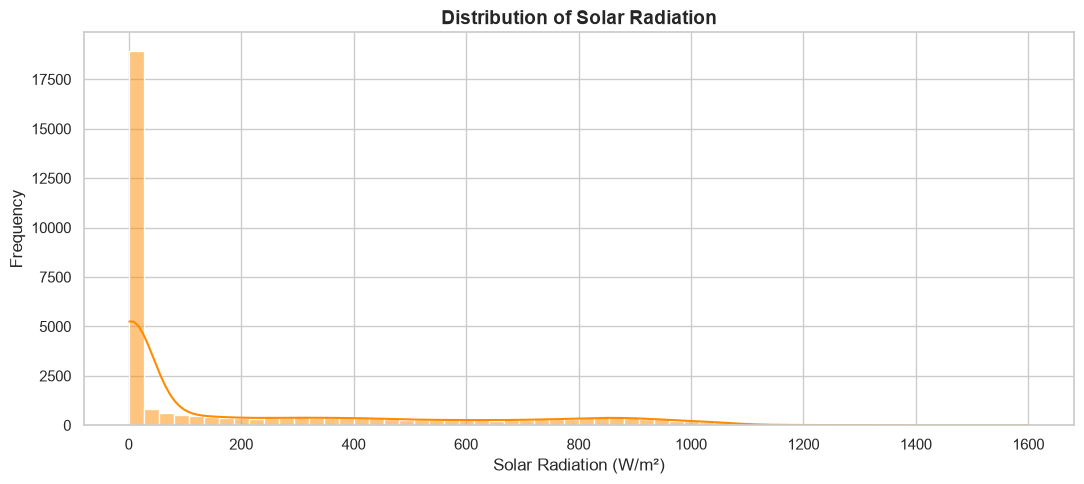

In [12]:

# Section 4.1: Solar Radiation Distribution and Variability

from pathlib import Path

# Define the figure directory once for reuse
figures_dir = Path("../figures")
figures_dir.mkdir(parents=True, exist_ok=True)

# Use the previously prepared dataset
radiation_values = df_features["Radiation"].dropna()

fig, ax = plt.subplots(figsize=(11, 5))

sns.histplot(
    radiation_values,
    bins=60,
    kde=True,
    color="darkorange",
    edgecolor="white",
    ax=ax
)

ax.set_title(
    "Distribution of Solar Radiation",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Solar Radiation (W/m²)")
ax.set_ylabel("Frequency")

plt.tight_layout()

# Save the figure in high resolution
fig.savefig(
    figures_dir / "4_1_solar_radiation_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the figure
plt.show()


#### 4.1.1 Interpretation of Solar Radiation Distribution

The solar radiation histogram exhibits a strongly right-skewed distribution, characterized by a substantial concentration of observations at low radiation levels and a long tail extending toward higher values.

The high frequency of near-zero radiation measurements is consistent with nighttime conditions, although low radiation may also occur during cloudy periods and around sunrise or sunset.

The distribution demonstrates considerable variability in solar radiation intensity, reflecting changing solar and atmospheric conditions throughout the observation period.

From an energy perspective, these findings highlight the intermittent nature of solar resource availability and the importance of understanding temporal radiation patterns for renewable energy planning.

From a forecasting perspective, the dominance of low-radiation observations may influence model performance. Therefore, subsequent model evaluation should consider prediction accuracy under both low- and high-radiation conditions.

Overall, the distribution analysis establishes the variability of the prediction target and provides a foundation for investigating diurnal and longer-term radiation patterns.

### 4.2 Diurnal Solar Radiation Patterns

Solar radiation follows a daily cycle influenced by the Earth's rotation, solar position, and atmospheric conditions.

This analysis examines the average solar radiation recorded at different hours of the day to identify typical periods of low and high solar resource availability.

The findings will provide insights into daily solar radiation variability, potential peak solar resource periods, and the importance of time-of-day information for forecasting.

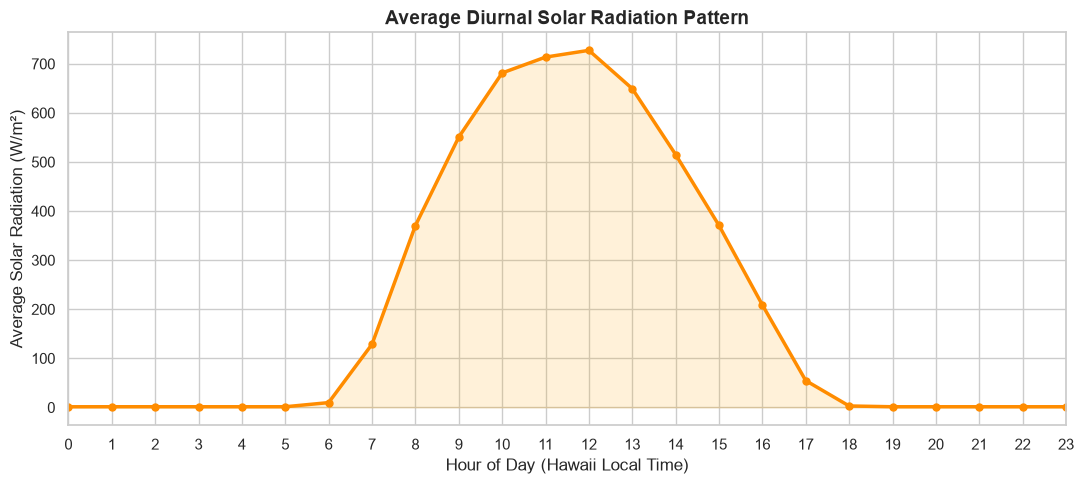

In [13]:

# Section 4.2: Diurnal Solar Radiation Patterns

# Calculate mean radiation by local hour
hourly_radiation = (
    df_features["Radiation"]
    .groupby(df_features.index.hour)
    .mean()
)

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    hourly_radiation.index,
    hourly_radiation.values,
    color="darkorange",
    linewidth=2.5,
    marker="o",
    markersize=5
)

ax.fill_between(
    hourly_radiation.index,
    hourly_radiation.values,
    color="orange",
    alpha=0.15
)

ax.set_title(
    "Average Diurnal Solar Radiation Pattern",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Hour of Day (Hawaii Local Time)")
ax.set_ylabel("Average Solar Radiation (W/m²)")
ax.set_xticks(range(24))
ax.set_xlim(0, 23)

plt.tight_layout()

# Save high-resolution figure
fig.savefig(
    figures_dir / "4_2_diurnal_solar_radiation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


#### 4.2.1 Interpretation of Diurnal Solar Radiation Patterns

The diurnal analysis reveals a clear daily solar radiation cycle, characterized by low radiation levels during nighttime and increasing radiation intensity after sunrise.

Average solar radiation begins increasing around 6:00 AM and reaches its maximum of approximately 725 W/m² at 12:00 PM. Radiation subsequently declines throughout the afternoon, approaching zero around 6:00 PM.

The highest average radiation levels occur approximately between 9:00 AM and 3:00 PM, indicating the period of greatest solar resource availability.

These findings demonstrate the strong influence of time of day on solar radiation intensity and highlight the importance of temporal patterns in solar energy forecasting.

The observed daily cycle also supports the use of cyclical time features developed during preprocessing, which can help prediction models capture recurring variations in solar radiation.

### 4.3 Monthly Solar Radiation Variability

This section examines variations in average solar radiation across the months covered by the dataset (September–December 2016).

The objective is to identify monthly differences in solar radiation intensity, assess temporal variability, and understand their implications for solar energy availability and prediction.

Monthly averages are calculated using available observations to avoid treating missing measurements as zero radiation.

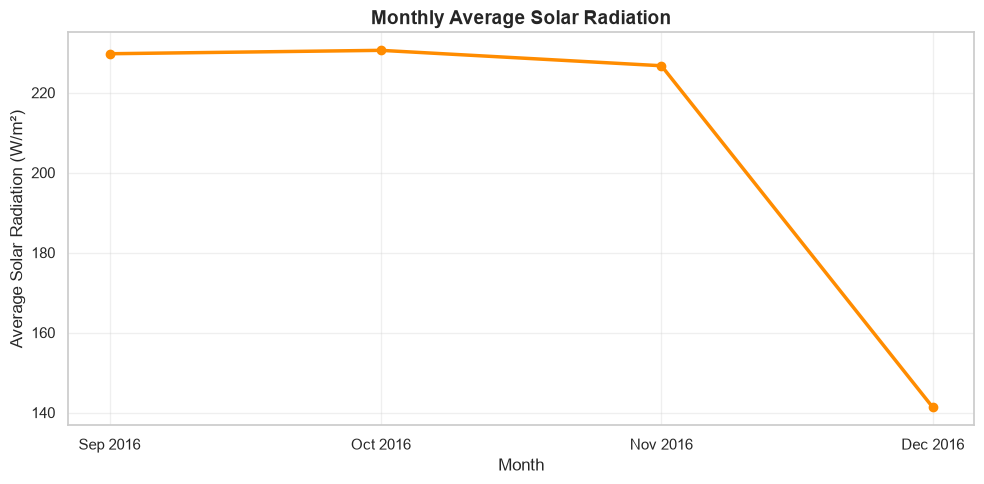

In [14]:
# Section 4.3 — Monthly Solar Radiation Variability

# Calculate monthly average solar radiation
monthly_radiation = (
    df_features["Radiation"]
    .resample("MS")
    .mean()
)

# Create the visualization
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    monthly_radiation.index,
    monthly_radiation.values,
    marker="o",
    linewidth=2.5,
    color="darkorange"
)

ax.set_title(
    "Monthly Average Solar Radiation",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Month")
ax.set_ylabel("Average Solar Radiation (W/m²)")

ax.set_xticks(monthly_radiation.index)
ax.set_xticklabels(
    monthly_radiation.index.strftime("%b %Y")
)

ax.grid(True, alpha=0.3)

plt.tight_layout()

# Save the figure
fig.savefig(
    "../figures/monthly_average_solar_radiation.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the figure
plt.show()

### Interpretation of Monthly Solar Radiation Variability

The monthly analysis reveals relatively stable average solar radiation between September and November 2016, with October recording the highest average at approximately 231 W/m².

A substantial decline is observed in December, when average radiation falls to approximately 141 W/m², representing a reduction of about 39% compared with October.

This variation suggests that solar resource availability changes across the observed months, with potential implications for solar energy generation and forecasting.

However, the monthly averages are based on available measurements, including nighttime observations. Missing data intervals and differences in monthly coverage may influence the results. Therefore, the observed pattern should not be interpreted as a definitive seasonal trend without further investigation.

### 4.4 Relationship Between Solar Radiation and Meteorological Variables

This section investigates the relationships between solar radiation and selected meteorological variables, including temperature, humidity, atmospheric pressure, and wind speed.

A correlation heatmap is used to examine the strength and direction of linear relationships between these variables.

The analysis provides preliminary insights into potential predictors of solar radiation. However, correlation does not imply causation.

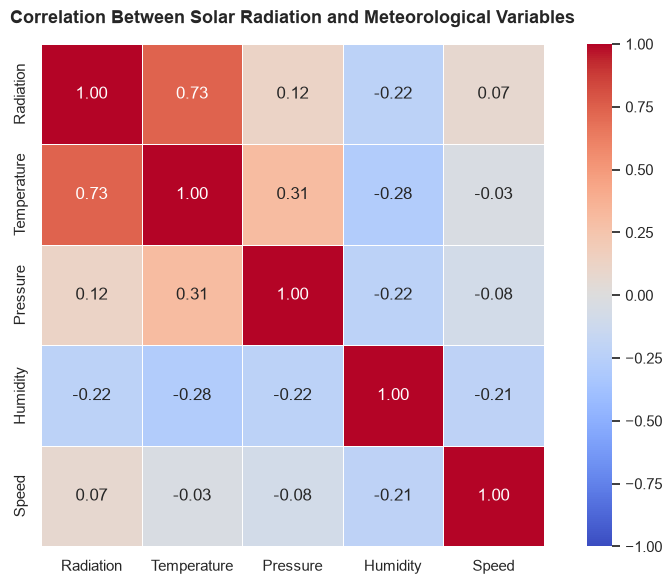

In [15]:
# Section 4.4 — Correlation Analysis

# Select existing meteorological variables
correlation_cols = [
    "Radiation",
    "Temperature",
    "Pressure",
    "Humidity",
    "Speed"
]

# Calculate the Pearson correlation matrix
correlation_matrix = df_features[correlation_cols].corr()

# Create the correlation heatmap
fig, ax = plt.subplots(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True,
    ax=ax
)

ax.set_title(
    "Correlation Between Solar Radiation and Meteorological Variables",
    fontsize=13,
    fontweight="bold",
    pad=15
)

plt.tight_layout()

# Save the figure
fig.savefig(
    "../figures/solar_radiation_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the figure
plt.show()

### Interpretation of Correlation Analysis

The correlation analysis reveals varying degrees of linear association between solar radiation and the selected meteorological variables.

Temperature exhibits the strongest positive correlation with solar radiation (r = 0.73), indicating that higher temperatures generally coincide with higher solar radiation measurements.

Humidity demonstrates a weak negative correlation (r = -0.22), suggesting that increasing humidity is associated with slightly lower solar radiation levels.

Atmospheric pressure (r = 0.12) and wind speed (r = 0.07) exhibit weak and very weak positive correlations, respectively, indicating limited linear relationships with solar radiation.

**Implications for Solar Radiation Prediction**

Temperature emerges as a potentially important predictor of solar radiation. However, the remaining meteorological variables may still contribute useful information through nonlinear relationships and interactions.

These findings provide preliminary guidance for feature selection during predictive modeling. Correlation does not establish causation, and predictive importance must be evaluated using appropriate time-series validation techniques.

### 4.5 Daytime vs. Nighttime Solar Radiation Analysis

This section investigates the distribution of solar radiation during daylight and nighttime periods.

The objective is to understand how solar radiation measurements differ between these periods and assess the implications for solar radiation forecasting.

Daytime and nighttime observations are identified using the sunrise and sunset information available in the original dataset.

Daytime and Nighttime Observation Counts:


Period
Nighttime    17078
Daytime      15606
Name: count, dtype: int64


Average Solar Radiation by Period (W/m²):


Period
Daytime     432.21
Nighttime     1.41
Name: Radiation, dtype: float64

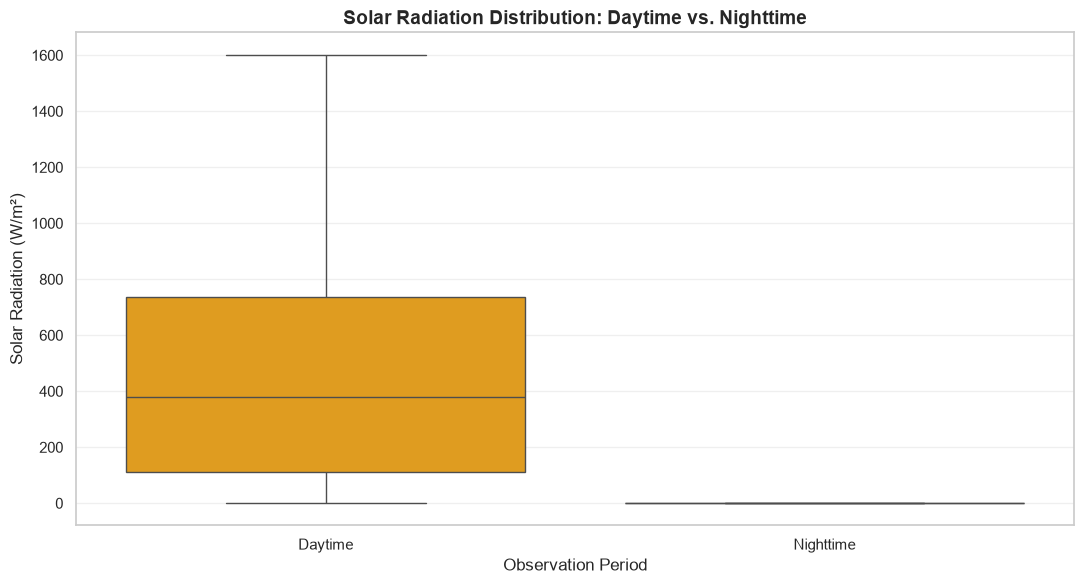

In [16]:
# Section 4.5 — Daytime vs. Nighttime Solar Radiation Analysis

# Extract solar radiation from the existing feature dataset
day_night_df = df_features[["Radiation"]].copy()

# Convert sunrise and sunset times to minutes after midnight
sunrise_minutes = (
    pd.to_timedelta(df_clean["TimeSunRise"].astype(str))
    .dt.total_seconds() / 60
)

sunset_minutes = (
    pd.to_timedelta(df_clean["TimeSunSet"].astype(str))
    .dt.total_seconds() / 60
)

# Recover observation dates from UNIX timestamps (Hawaii local time)
original_dates = (
    pd.to_datetime(df_clean["UNIXTime"], unit="s", utc=True)
    .dt.tz_convert("Pacific/Honolulu")
    .dt.date
)

# Associate sunrise and sunset with their observation dates
sun_times = pd.DataFrame({
    "Date": original_dates.to_numpy(),
    "Sunrise": sunrise_minutes.to_numpy(),
    "Sunset": sunset_minutes.to_numpy()
})

# Calculate daily sunrise and sunset times
daily_sun_times = (
    sun_times.groupby("Date")[["Sunrise", "Sunset"]]
    .median()
)

# Ensure feature timestamps use Hawaii local time
if day_night_df.index.tz is None:
    raise ValueError(
        "df_features must have a timezone-aware DatetimeIndex. "
        "Check the timestamp preprocessing in Section 3."
    )

local_index = day_night_df.index.tz_convert("Pacific/Honolulu")

# Align daily sunrise and sunset times with the feature dataset
feature_dates = pd.Index(local_index.date)

day_night_df["Sunrise"] = (
    daily_sun_times["Sunrise"]
    .reindex(feature_dates)
    .to_numpy()
)

day_night_df["Sunset"] = (
    daily_sun_times["Sunset"]
    .reindex(feature_dates)
    .to_numpy()
)

# Convert observation timestamps to minutes after midnight
observation_minutes = (
    local_index.hour * 60
    + local_index.minute
    + local_index.second / 60
)

# Classify daytime and nighttime using sunrise and sunset
daytime_mask = (
    (observation_minutes >= day_night_df["Sunrise"])
    & (observation_minutes < day_night_df["Sunset"])
)

day_night_df["Period"] = np.where(
    daytime_mask,
    "Daytime",
    "Nighttime"
)

# Exclude observations without valid radiation or sun-time data
day_night_df = day_night_df.dropna(
    subset=["Radiation", "Sunrise", "Sunset"]
)

# Display classification summary
print("Daytime and Nighttime Observation Counts:")
display(day_night_df["Period"].value_counts())

print("\nAverage Solar Radiation by Period (W/m²):")
display(
    day_night_df.groupby("Period")["Radiation"]
    .mean()
    .round(2)
)

# Create daytime versus nighttime radiation boxplot
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=day_night_df,
    x="Period",
    y="Radiation",
    order=["Daytime", "Nighttime"],
    color="orange",
    showfliers=False
)

plt.title(
    "Solar Radiation Distribution: Daytime vs. Nighttime",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Observation Period")
plt.ylabel("Solar Radiation (W/m²)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Use the existing figures directory in the project root
figures_dir = Path.cwd().parent / "figures"


# Save figure in the existing project figures folder
plt.savefig(
    "../figures/daytime_vs_nighttime_radiation.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the figure
plt.show()



In [17]:
# Section 4.5 - Check nighttime solar radiation statistics

# Extract nighttime radiation from the existing DataFrame
nighttime_radiation = day_night_df.loc[
    day_night_df["Period"] == "Nighttime", "Radiation"
]

# Display descriptive statistics
print("Nighttime Solar Radiation Statistics:")
print(nighttime_radiation.describe())

# Check nighttime readings above 10 W/m²
print(
    "\nNighttime readings above 10 W/m²:",
    (nighttime_radiation > 10).sum()
)

# Check maximum nighttime radiation
print(
    "\nMaximum nighttime radiation (W/m²):",
    nighttime_radiation.max()
)

Nighttime Solar Radiation Statistics:
count   17078.00
mean        1.41
std         0.60
min         1.11
25%         1.21
50%         1.23
75%         1.26
max        15.75
Name: Radiation, dtype: float64

Nighttime readings above 10 W/m²: 2

Maximum nighttime radiation (W/m²): 15.75


### Interpretation of Daytime and Nighttime Solar Radiation

The analysis reveals a clear difference between daytime and nighttime solar radiation. Daytime observations recorded an average radiation intensity of 432.21 W/m², compared with only 1.41 W/m² during nighttime.

Nighttime radiation measurements remained consistently low, with a median of 1.23 W/m². Only two nighttime observations exceeded 10 W/m², while the maximum recorded value was 15.75 W/m².

The small positive nighttime measurements may indicate sensor offset or measurement noise. These values require further investigation before applying any correction.

Overall, the results confirm the strong influence of daylight availability on solar radiation and highlight the importance of considering day-night patterns when developing solar radiation prediction models.

In [18]:
# Section 4.5 - Inspect unusual nighttime radiation readings

unusual_nighttime = day_night_df.loc[
    (day_night_df["Period"] == "Nighttime") &
    (day_night_df["Radiation"] > 10)
]

print("Unusual Nighttime Solar Radiation Observations:")
display(unusual_nighttime)

Unusual Nighttime Solar Radiation Observations:


,Radiation,Sunrise,Sunset,Period
Datetime,,,,
2016-12-20 06:45:00-10:00,10.93,412.00,1068.00,Nighttime
2016-12-20 06:50:00-10:00,15.75,412.00,1068.00,Nighttime


Further investigation identified two elevated nighttime radiation readings of 10.93 W/m² and 15.75 W/m², recorded at 06:45 and 06:50 on 20 December 2016, respectively. Both observations occurred shortly before the recorded sunrise at 06:52. These measurements may be associated with dawn twilight rather than sensor errors. Consequently, the observations were retained without modification.


## 5. Solar Radiation Prediction and Machine Learning

This section develops and evaluates machine learning models for predicting solar radiation using meteorological and temporal information.

Building on the preprocessing, feature engineering, and exploratory analysis completed in Sections 3 and 4, the objective is to assess how effectively historical weather observations can support solar radiation prediction.

The analysis will compare predictive approaches, beginning with a simple baseline and progressing to more advanced models.

### 5.1 Modeling Objective and Data Preparation

The target variable is **Radiation (W/m²)**.

The modeling process will reuse the existing feature-engineered dataset (`df_features`) to avoid duplicating preprocessing operations.

The main preparation steps include:

- Selecting relevant predictor variables.
- Defining the prediction target and forecast horizon.
- Separating training and testing observations chronologically.
- Preventing data leakage during model training.
- Establishing a consistent evaluation framework for model comparison.

Model performance will be assessed using appropriate regression metrics, including MAE, RMSE, and R².


In [19]:

# Section 5.1 — Verify temporal spacing for forecasting

# Calculate time intervals between consecutive observations
time_intervals = df_features.index.to_series().diff().dropna()

# Summarize the most common observation intervals
print("Most common observation intervals:")
display(time_intervals.value_counts().head(10))

# Check the number of valid consecutive 5-minute intervals
five_minute_intervals = (
    time_intervals == pd.Timedelta(minutes=5)
)

print(
    f"\nConsecutive 5-minute intervals: "
    f"{five_minute_intervals.sum():,}"
)

print(
    f"Other intervals: "
    f"{(~five_minute_intervals).sum():,}"
)


Most common observation intervals:


Datetime
0 days 00:05:00    35135
Name: count, dtype: int64


Consecutive 5-minute intervals: 35,135
Other intervals: 0


In [20]:

# Section 5.1 — Prepare the 5-minute-ahead prediction dataset

# Reuse the existing feature-engineered dataset
model_df = df_features.copy()

# Create the prediction target: radiation 5 minutes ahead
model_df["Radiation_t_plus_5"] = model_df["Radiation"].shift(-1)

# Remove the final observation without a future target
model_df = model_df.dropna(subset=["Radiation_t_plus_5"])

# Separate predictors and target
X = model_df.drop(columns=["Radiation_t_plus_5"])
y = model_df["Radiation_t_plus_5"]

# Verify the modeling dataset
print(f"Modeling observations: {len(model_df):,}")
print(f"Number of predictors: {X.shape[1]}")
print(f"Target variable: {y.name}")

display(model_df.head())


Modeling observations: 32,683
Number of predictors: 12
Target variable: Radiation_t_plus_5


,Radiation,Temperature,Pressure,Humidity,Speed,WindDirection(Degrees),Hour_sin,Hour_cos,Day_sin,Day_cos,Wind_sin,Wind_cos,Radiation_t_plus_5
Datetime,,,,,,,,,,,,,
2016-09-01 00:00:00-10:00,2.58,51.00,30.43,100.00,11.25,77.27,0.00,1.00,-0.87,-0.49,0.98,0.22,2.83
2016-09-01 00:15:00-10:00,NaN,NaN,NaN,NaN,NaN,NaN,0.07,1.00,-0.87,-0.49,NaN,NaN,2.16
2016-09-01 00:20:00-10:00,2.16,51.00,30.43,100.00,7.87,142.04,0.09,1.00,-0.87,-0.49,0.62,-0.79,2.21
2016-09-01 00:25:00-10:00,2.21,51.00,30.43,100.00,18.00,144.12,0.11,0.99,-0.87,-0.49,0.59,-0.81,2.25
2016-09-01 00:40:00-10:00,NaN,NaN,NaN,NaN,NaN,NaN,0.17,0.98,-0.87,-0.49,NaN,NaN,2.15


In [21]:

# Keep only complete predictor-target pairs for modeling
model_df = model_df.dropna(subset=X.columns.tolist() + ["Radiation_t_plus_5"]).copy()

# Update predictors and target
X = model_df.drop(columns=["Radiation_t_plus_5"])
y = model_df["Radiation_t_plus_5"]

# Verify that the modeling dataset contains no missing values
print(f"Valid modeling observations: {len(model_df):,}")
print(f"Missing predictor values: {X.isna().sum().sum():,}")
print(f"Missing target values: {y.isna().sum():,}")

Valid modeling observations: 32,375
Missing predictor values: 0
Missing target values: 0


In [22]:

# Section 5.1 — Chronological train/test split

# Define the split point
split_idx = int(len(X) * 0.80)

# Preserve chronological order
X_train = X.iloc[:split_idx].copy()
X_test = X.iloc[split_idx:].copy()

y_train = y.iloc[:split_idx].copy()
y_test = y.iloc[split_idx:].copy()

# Verify the split
print(f"Training observations: {len(X_train):,}")
print(f"Testing observations: {len(X_test):,}")

print(f"\nTraining period: {X_train.index.min()} to {X_train.index.max()}")
print(f"Testing period: {X_test.index.min()} to {X_test.index.max()}")

print(f"\nTraining missing values: {X_train.isna().sum().sum():,}")
print(f"Testing missing values: {X_test.isna().sum().sum():,}")


Training observations: 25,900
Testing observations: 6,475

Training period: 2016-09-01 00:00:00-10:00 to 2016-12-09 09:45:00-10:00
Testing period: 2016-12-09 09:50:00-10:00 to 2016-12-31 23:50:00-10:00

Training missing values: 0
Testing missing values: 0



### 5.2 Persistence Baseline Model

A persistence model is established as a benchmark for evaluating subsequent machine learning models.

For the five-minute forecasting horizon, the baseline assumes that solar radiation remains unchanged between consecutive observations.

The model uses the current radiation measurement to predict radiation five minutes ahead.

Performance is evaluated on the chronological test dataset using:

- **Mean Absolute Error (MAE):** Average absolute prediction error.
- **Root Mean Squared Error (RMSE):** Measures prediction error while penalizing larger deviations.
- **Coefficient of Determination (R²):** Measures predictive performance relative to predicting the mean of the test observations.

This baseline provides a reference for determining whether more advanced models offer meaningful improvements.


In [23]:

# Section 5.2 — Persistence Baseline Model

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict future radiation using the current radiation measurement
y_pred_baseline = X_test["Radiation"].copy()

# Evaluate baseline performance
baseline_mae = mean_absolute_error(y_test, y_pred_baseline)
baseline_rmse = np.sqrt(mean_squared_error(y_test, y_pred_baseline))
baseline_r2 = r2_score(y_test, y_pred_baseline)

# Display evaluation results
print("Persistence Baseline Model Performance")
print("-" * 40)
print(f"MAE  : {baseline_mae:.2f} W/m²")
print(f"RMSE : {baseline_rmse:.2f} W/m²")
print(f"R²   : {baseline_r2:.4f}")


Persistence Baseline Model Performance
----------------------------------------
MAE  : 22.45 W/m²
RMSE : 69.36 W/m²
R²   : 0.9321



#### Interpretation of Persistence Baseline Results

The persistence baseline achieved a Mean Absolute Error (MAE) of 22.45 W/m², a Root Mean Squared Error (RMSE) of 69.36 W/m², and an R² score of 0.9321 on the test dataset.

These results indicate that current solar radiation measurements provide substantial predictive information for radiation five minutes ahead.

The relatively high R² score suggests strong short-term continuity in solar radiation. However, the difference between MAE and RMSE indicates that some predictions experience considerably larger errors, potentially associated with rapid atmospheric changes or cloud movement.

The persistence model therefore provides a strong benchmark for subsequent machine learning models. More advanced approaches will be evaluated based on whether they achieve lower prediction errors and improved predictive performance on the same test dataset.



### 5.3 Linear Regression Model

Linear Regression is introduced as the first supervised machine learning model for predicting solar radiation five minutes ahead.

The model estimates the relationship between future solar radiation and the meteorological and temporal predictors prepared in Section 5.1.

Unlike the persistence baseline, which uses only the current radiation measurement, Linear Regression combines multiple predictor variables to estimate future radiation.

The model will be trained using the existing chronological training dataset and evaluated on the same test dataset used for the persistence baseline.

Performance will be assessed using MAE, RMSE, and R² to determine whether Linear Regression improves upon the persistence benchmark.


In [24]:

# Section 5.3 — Linear Regression Model

from sklearn.linear_model import LinearRegression

# Initialize and train the model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predict solar radiation 5 minutes ahead
y_pred_lr = lr_model.predict(X_test)

# Evaluate model performance
lr_mae = mean_absolute_error(y_test, y_pred_lr)
lr_rmse = np.sqrt(mean_squared_error(y_test, y_pred_lr))
lr_r2 = r2_score(y_test, y_pred_lr)

# Display results
print("Linear Regression Model Performance")
print("-" * 40)
print(f"MAE  : {lr_mae:.2f} W/m²")
print(f"RMSE : {lr_rmse:.2f} W/m²")
print(f"R²   : {lr_r2:.4f}")

# Compare against the persistence baseline
print("\nComparison with Persistence Baseline")
print("-" * 40)
print(f"MAE improvement  : {baseline_mae - lr_mae:+.2f} W/m²")
print(f"RMSE improvement : {baseline_rmse - lr_rmse:+.2f} W/m²")
print(f"R² improvement   : {lr_r2 - baseline_r2:+.4f}")

Linear Regression Model Performance
----------------------------------------
MAE  : 36.89 W/m²
RMSE : 69.57 W/m²
R²   : 0.9317

Comparison with Persistence Baseline
----------------------------------------
MAE improvement  : -14.44 W/m²
RMSE improvement : -0.21 W/m²
R² improvement   : -0.0004



#### Interpretation of Linear Regression Results

The Linear Regression model achieved an MAE of 36.89 W/m², an RMSE of 69.57 W/m², and an R² score of 0.9317.

Compared with the persistence baseline, Linear Regression produced a higher MAE by 14.44 W/m² and a slightly higher RMSE by 0.21 W/m². Its R² score was also marginally lower.

These findings indicate that Linear Regression did not outperform the persistence baseline for five-minute-ahead solar radiation forecasting.

The strong performance of persistence suggests that short-term solar radiation is highly dependent on its most recent measurement. Although Linear Regression incorporates meteorological and temporal predictors, its linear structure may not adequately capture complex or nonlinear variations in solar radiation.

The results highlight the importance of evaluating advanced models against a simple benchmark rather than assuming that greater model complexity guarantees better predictions.

Subsequent models will investigate whether nonlinear machine learning approaches can improve forecasting accuracy.



### 5.4 Random Forest Regression Model

Random Forest Regression is implemented to investigate whether nonlinear machine learning techniques can improve five-minute-ahead solar radiation forecasting.

The model combines predictions from multiple decision trees, allowing it to capture complex relationships and interactions between meteorological conditions, temporal features, and solar radiation.

The existing chronological training and testing datasets are reused to maintain consistency with previous models and prevent data leakage.

Model performance will be evaluated using MAE, RMSE, and R² and compared with both the persistence baseline and Linear Regression.

The objective is to determine whether Random Forest provides meaningful improvements in forecasting accuracy.


In [25]:

# Section 5.4 — Random Forest Regression Model

from sklearn.ensemble import RandomForestRegressor

# Initialize the model with reproducible settings
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train using the existing chronological training dataset
rf_model.fit(X_train, y_train)

# Predict solar radiation 5 minutes ahead
y_pred_rf = rf_model.predict(X_test)

# Evaluate using the existing regression metrics
rf_mae = mean_absolute_error(y_test, y_pred_rf)
rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
rf_r2 = r2_score(y_test, y_pred_rf)

# Display model performance
print("Random Forest Model Performance")
print("-" * 40)
print(f"MAE  : {rf_mae:.2f} W/m²")
print(f"RMSE : {rf_rmse:.2f} W/m²")
print(f"R²   : {rf_r2:.4f}")

# Compare against the persistence baseline
print("\nComparison with Persistence Baseline")
print("-" * 40)
print(f"MAE improvement  : {baseline_mae - rf_mae:+.2f} W/m²")
print(f"RMSE improvement : {baseline_rmse - rf_rmse:+.2f} W/m²")
print(f"R² improvement   : {rf_r2 - baseline_r2:+.4f}")


Random Forest Model Performance
----------------------------------------
MAE  : 27.60 W/m²
RMSE : 68.74 W/m²
R²   : 0.9333

Comparison with Persistence Baseline
----------------------------------------
MAE improvement  : -5.15 W/m²
RMSE improvement : +0.62 W/m²
R² improvement   : +0.0012



#### Interpretation of Random Forest Results

The Random Forest Regression model achieved an MAE of 27.60 W/m², an RMSE of 68.74 W/m², and an R² score of 0.9333.

Compared with Linear Regression, Random Forest demonstrated better performance across all three evaluation metrics, suggesting that nonlinear relationships between meteorological variables and solar radiation are relevant to short-term forecasting.

Compared with the persistence baseline, Random Forest reduced RMSE by 0.62 W/m² and increased R² by 0.0012. However, its MAE was 5.15 W/m² higher.

These mixed results indicate that Random Forest provides a modest improvement in squared-error performance but does not consistently outperform the simpler persistence approach.

The findings demonstrate that greater model complexity does not necessarily guarantee better forecasting accuracy, particularly over a short five-minute prediction horizon.

Further evaluation of alternative machine learning approaches is necessary before selecting the most suitable forecasting model.



### 5.5 XGBoost Regression Model

XGBoost (Extreme Gradient Boosting) is introduced as an advanced ensemble learning algorithm for five-minute-ahead solar radiation prediction.

The model constructs decision trees sequentially, allowing subsequent trees to reduce prediction errors made by earlier trees. This approach can capture nonlinear relationships and complex interactions between meteorological and temporal variables.

The existing chronological training and testing datasets are reused to ensure consistent evaluation and prevent data leakage.

Model performance will be assessed using MAE, RMSE, and R² and compared with the persistence baseline, Linear Regression, and Random Forest models.

The objective is to investigate whether gradient boosting provides meaningful improvements in short-term solar radiation forecasting.


In [28]:

# Section 5.5 — XGBoost Regression Model

from xgboost import XGBRegressor

# Initialize XGBoost with reproducible settings
xgb_model = XGBRegressor(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# Train on the existing chronological training dataset
xgb_model.fit(X_train, y_train)

# Predict solar radiation 5 minutes ahead
y_pred_xgb = xgb_model.predict(X_test)

# Evaluate using the existing regression metrics
xgb_mae = mean_absolute_error(y_test, y_pred_xgb)
xgb_rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
xgb_r2 = r2_score(y_test, y_pred_xgb)

# Display model performance
print("XGBoost Model Performance")
print("-" * 40)
print(f"MAE  : {xgb_mae:.2f} W/m²")
print(f"RMSE : {xgb_rmse:.2f} W/m²")
print(f"R²   : {xgb_r2:.4f}")

# Compare with the persistence baseline
print("\nComparison with Persistence Baseline")
print("-" * 40)
print(f"MAE improvement  : {baseline_mae - xgb_mae:+.2f} W/m²")
print(f"RMSE improvement : {baseline_rmse - xgb_rmse:+.2f} W/m²")
print(f"R² improvement   : {xgb_r2 - baseline_r2:+.4f}")


XGBoost Model Performance
----------------------------------------
MAE  : 32.97 W/m²
RMSE : 73.87 W/m²
R²   : 0.9230

Comparison with Persistence Baseline
----------------------------------------
MAE improvement  : -10.52 W/m²
RMSE improvement : -4.51 W/m²
R² improvement   : -0.0091



#### Interpretation of XGBoost Results

The XGBoost Regression model achieved an MAE of 32.97 W/m², an RMSE of 73.87 W/m², and an R² score of 0.9230.

Compared with the persistence baseline, XGBoost produced a higher MAE by 10.52 W/m² and a higher RMSE by 4.51 W/m². Its R² score was also lower by 0.0091.

XGBoost also performed worse than Random Forest across all three evaluation metrics, indicating that gradient boosting did not provide an improvement under the selected model configuration.

Although XGBoost achieved relatively strong predictive performance, the results suggest that the current radiation measurement remains a particularly effective predictor for the five-minute forecasting horizon.

These findings reinforce the importance of benchmarking machine learning models against simpler forecasting approaches. Model complexity alone does not guarantee superior predictive accuracy.

Further investigation of temporal learning approaches may help determine whether explicitly modeling sequential patterns can improve short-term solar radiation forecasting.



### 5.6 Simple Recurrent Neural Network (RNN) Model

A Simple Recurrent Neural Network (RNN) is introduced to investigate whether learning temporal patterns from historical observations can improve five-minute-ahead solar radiation forecasting.

Unlike the previously implemented regression models, which use individual observations, an RNN processes sequences of consecutive measurements and maintains information from earlier time steps.

The model will use 12 consecutive five-minute observations, representing 60 minutes of historical data, to predict solar radiation five minutes after the final observation.

The existing chronological training and testing periods will be preserved. Feature scaling will be fitted using training data only, and sequence construction will exclude incomplete or discontinuous observation windows to prevent data leakage.

Model performance will be evaluated using MAE, RMSE, and R² and compared with the persistence baseline, Linear Regression, Random Forest, and XGBoost.

The same sequence preparation and evaluation framework will subsequently be reused for the LSTM model to ensure a fair comparison between recurrent architectures.


In [32]:

# Section 5.6 — Shared RNN/LSTM Sequence Preparation

from sklearn.preprocessing import StandardScaler

sequence_length = 12
expected_interval = pd.Timedelta(minutes=5)

# Fit scaling using training data only
sequence_scaler = StandardScaler()
sequence_scaler.fit(X_train)

# Transform existing modeling predictors
X_scaled = sequence_scaler.transform(X)

# Identify consecutive observation groups
time_gaps = X.index.to_series().diff()
group_ids = time_gaps.ne(expected_interval).cumsum()

# Prepare sequences without crossing missing-data gaps
X_seq_list = []
y_seq_list = []
seq_time_list = []

for _, group in X.groupby(group_ids):
    positions = X.index.get_indexer(group.index)

    if len(positions) < sequence_length:
        continue

    for end in range(sequence_length - 1, len(positions)):
        window_positions = positions[
            end - sequence_length + 1:end + 1
        ]

        X_seq_list.append(X_scaled[window_positions])
        y_seq_list.append(y.iloc[positions[end]])
        seq_time_list.append(X.index[positions[end]])

# Convert to arrays
X_seq = np.asarray(X_seq_list, dtype=np.float32)
y_seq = np.asarray(y_seq_list, dtype=np.float32)
seq_times = pd.DatetimeIndex(seq_time_list)

# Split sequences using the original chronological boundary
train_mask = seq_times < X_test.index.min()
test_mask = seq_times >= X_test.index.min()

X_train_seq = X_seq[train_mask]
y_train_seq = y_seq[train_mask]

X_test_seq = X_seq[test_mask]
y_test_seq = y_seq[test_mask]

test_seq_times = seq_times[test_mask]

# Verify dimensions
print("Training sequences:", X_train_seq.shape)
print("Testing sequences:", X_test_seq.shape)
print("Training targets:", y_train_seq.shape)
print("Testing targets:", y_test_seq.shape)

print("\nChronological separation:")
print("Last training target:", seq_times[train_mask].max())
print("First testing target:", test_seq_times.min())


Training sequences: (23816, 12, 12)
Testing sequences: (6320, 12, 12)
Training targets: (23816,)
Testing targets: (6320,)

Chronological separation:
Last training target: 2016-12-09 09:45:00-10:00
First testing target: 2016-12-09 09:50:00-10:00


In [35]:

# Section 5.6 — Simple RNN Model Training

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, SimpleRNN, Dense
from tensorflow.keras.callbacks import EarlyStopping

# Set random seeds for reproducibility
tf.keras.utils.set_random_seed(42)

# Define the Simple RNN architecture
rnn_model = Sequential([
    Input(shape=(X_train_seq.shape[1], X_train_seq.shape[2])),
    SimpleRNN(32, activation="tanh"),
    Dense(16, activation="relu"),
    Dense(1)
])

# Configure model training
rnn_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

# Stop training when validation performance stops improving
rnn_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Train using chronological validation data
rnn_history = rnn_model.fit(
    X_train_seq,
    y_train_seq,
    epochs=30,
    batch_size=64,
    validation_split=0.2,
    shuffle=False,
    callbacks=[rnn_early_stopping],
    verbose=1
)

# Display the model architecture
rnn_model.summary()


Epoch 1/30
298/298 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - loss: 160682.0469 - mae: 230.0588 - val_loss: 78679.3516 - val_mae: 142.5093
Epoch 2/30
298/298 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 137717.2500 - mae: 211.9260 - val_loss: 61320.8008 - val_mae: 119.5977
Epoch 3/30
298/298 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 110459.6562 - mae: 187.2849 - val_loss: 47074.1758 - val_mae: 108.7368
Epoch 4/30
298/298 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 83177.3281 - mae: 156.6801 - val_loss: 32106.2363 - val_mae: 86.8522
Epoch 5/30
298/298 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 57973.4180 - mae: 125.2360 - val_loss: 21506.5547 - val_mae: 71.6044
Epoch 6/30
298/298 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 39877.5000 - mae: 102.2743 - val_loss: 15914.9922 - val_mae: 66.0001
Epoch 7/30
298/298 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 28501.5723 - mae: 88.3075 - val_loss: 10665.3018 - val_mae: 53.7629
Epoch 8/30
298/298 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 20402.7832 - mae: 74.4268 - val

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,957 (23.27 KB)

 Trainable params: 1,985 (7.75 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 3,972 (15.52 KB)

In [36]:

# Section 5.6 — Simple RNN Model Evaluation

# Predict solar radiation five minutes ahead
y_pred_rnn = rnn_model.predict(X_test_seq, verbose=0).ravel()

# Evaluate using the existing regression metrics
rnn_mae = mean_absolute_error(y_test_seq, y_pred_rnn)
rnn_rmse = np.sqrt(mean_squared_error(y_test_seq, y_pred_rnn))
rnn_r2 = r2_score(y_test_seq, y_pred_rnn)

# Display evaluation results
print("Simple RNN Model Performance")
print("-" * 40)
print(f"MAE  : {rnn_mae:.2f} W/m²")
print(f"RMSE : {rnn_rmse:.2f} W/m²")
print(f"R²   : {rnn_r2:.4f}")


Simple RNN Model Performance
----------------------------------------
MAE  : 38.93 W/m²
RMSE : 79.94 W/m²
R²   : 0.9091



#### Interpretation of Simple RNN Results

The Simple Recurrent Neural Network (RNN) achieved an MAE of 38.93 W/m², an RMSE of 79.94 W/m², and an R² score of 0.9091 on 6,320 valid testing sequences.

These results demonstrate that the RNN can learn useful temporal relationships from historical solar radiation and meteorological observations. However, the relatively high prediction errors indicate that the initial RNN configuration has limitations in forecasting short-term radiation fluctuations.

The model uses 12 consecutive five-minute observations to predict radiation five minutes ahead. This allows it to incorporate historical information rather than relying solely on the current observation.

Although the RNN's reported performance is weaker than that of the previously evaluated models, a definitive comparison requires evaluation on identical testing timestamps because sequence construction excluded some observations.

The next stage introduces an LSTM architecture to investigate whether its memory mechanisms can improve temporal learning and forecasting accuracy.



### 5.7 Long Short-Term Memory (LSTM) Model

Long Short-Term Memory (LSTM) is an advanced recurrent neural network architecture designed to learn temporal dependencies in sequential data while mitigating the vanishing-gradient problem associated with traditional RNNs.

Unlike the Simple RNN, LSTM uses memory cells and gating mechanisms to control the flow of information across time steps. These mechanisms allow the model to retain relevant historical information and potentially capture more complex temporal relationships.

For this study, the LSTM model uses the same 12-step historical observation sequences prepared in Section 5.6 to predict solar radiation five minutes ahead.

The existing scaled training and testing sequences are reused without repeating preprocessing or feature engineering. A comparable training configuration will be adopted to support a meaningful comparison between the RNN and LSTM architectures.

Model performance will be evaluated using MAE, RMSE, and R² on the same 6,320 testing sequences used for the Simple RNN.

The objective is to determine whether LSTM's memory mechanisms provide measurable improvements in short-term solar radiation forecasting.


In [37]:

# Section 5.7 — LSTM Model Training

from tensorflow.keras.layers import LSTM

# Set random seed for reproducibility
tf.keras.utils.set_random_seed(42)

# Define the LSTM architecture
lstm_model = Sequential([
    Input(shape=(X_train_seq.shape[1], X_train_seq.shape[2])),
    LSTM(32, activation="tanh"),
    Dense(16, activation="relu"),
    Dense(1)
])

# Compile the model
lstm_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

# Stop training when validation performance stops improving
lstm_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Train using the same chronological validation strategy as RNN
lstm_history = lstm_model.fit(
    X_train_seq,
    y_train_seq,
    epochs=30,
    batch_size=64,
    validation_split=0.2,
    shuffle=False,
    callbacks=[lstm_early_stopping],
    verbose=1
)

# Display the model architecture
lstm_model.summary()


Epoch 1/30
298/298 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 161540.0625 - mae: 229.4648 - val_loss: 78592.0156 - val_mae: 140.2540
Epoch 2/30
298/298 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 140383.5469 - mae: 209.5458 - val_loss: 63535.5156 - val_mae: 120.6833
Epoch 3/30
298/298 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 113541.4453 - mae: 182.8569 - val_loss: 47576.8125 - val_mae: 103.1999
Epoch 4/30
298/298 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 86349.5547 - mae: 154.7497 - val_loss: 34621.2891 - val_mae: 89.2396
Epoch 5/30
298/298 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 62983.9023 - mae: 128.7755 - val_loss: 26776.3438 - val_mae: 81.6288
Epoch 6/30
298/298 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 45238.0508 - mae: 107.9679 - val_loss: 20328.7617 - val_mae: 71.6568
Epoch 7/30
298/298 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 32254.0215 - mae: 90.8082 - val_loss: 14099.2715 - val_mae: 59.7891
Epoch 8/30
298/298 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 23070.5371 - mae: 76.2771 - val_

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         5,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,917 (73.90 KB)

 Trainable params: 6,305 (24.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,612 (49.27 KB)

In [38]:

# Section 5.7 — LSTM Model Evaluation

# Predict solar radiation five minutes ahead
y_pred_lstm = lstm_model.predict(X_test_seq, verbose=0).ravel()

# Evaluate using the existing regression metrics
lstm_mae = mean_absolute_error(y_test_seq, y_pred_lstm)
lstm_rmse = np.sqrt(mean_squared_error(y_test_seq, y_pred_lstm))
lstm_r2 = r2_score(y_test_seq, y_pred_lstm)

# Display evaluation results
print("LSTM Model Performance")
print("-" * 40)
print(f"MAE  : {lstm_mae:.2f} W/m²")
print(f"RMSE : {lstm_rmse:.2f} W/m²")
print(f"R²   : {lstm_r2:.4f}")

# Compare directly with Simple RNN on identical test sequences
print("\nComparison with Simple RNN")
print("-" * 40)
print(f"MAE improvement  : {rnn_mae - lstm_mae:+.2f} W/m²")
print(f"RMSE improvement : {rnn_rmse - lstm_rmse:+.2f} W/m²")
print(f"R² improvement   : {lstm_r2 - rnn_r2:+.4f}")


LSTM Model Performance
----------------------------------------
MAE  : 40.36 W/m²
RMSE : 80.10 W/m²
R²   : 0.9087

Comparison with Simple RNN
----------------------------------------
MAE improvement  : -1.43 W/m²
RMSE improvement : -0.16 W/m²
R² improvement   : -0.0004



#### Interpretation of LSTM Results

The Long Short-Term Memory (LSTM) model achieved an MAE of 40.36 W/m², an RMSE of 80.10 W/m², and an R² score of 0.9087 on 6,320 testing sequences.

Although the LSTM demonstrated strong predictive capability, it did not outperform the Simple RNN under the selected training configuration. The Simple RNN achieved a lower MAE (38.93 W/m²), a lower RMSE (79.94 W/m²), and a slightly higher R² score (0.9091).

The LSTM contained 6,305 trainable parameters compared with 1,985 for the Simple RNN. Despite this additional complexity, its forecasting accuracy was slightly lower.

These findings suggest that the LSTM's additional memory mechanisms did not provide a measurable advantage for the current five-minute-ahead solar radiation prediction task. However, different hyperparameters, longer input sequences, or additional training experiments could produce different outcomes.

Because both models were evaluated on identical testing sequences, their performance can be compared directly. A broader comparison with the conventional machine learning models will be conducted in the subsequent model evaluation section.



## 6.0 Model Evaluation and Comparison

### Overview

This section presents a comprehensive evaluation and comparison of the six forecasting approaches developed in Section 5:

1. Persistence Baseline
2. Linear Regression
3. Random Forest Regression
4. XGBoost Regression
5. Simple Recurrent Neural Network (RNN)
6. Long Short-Term Memory (LSTM)

The objective is to identify the most effective approach for predicting solar radiation five minutes ahead, considering forecasting accuracy, model complexity, and practical applicability.

### Evaluation Methodology

Model performance is assessed using three regression metrics:

- **Mean Absolute Error (MAE):** Measures the average absolute difference between predicted and observed solar radiation.
- **Root Mean Squared Error (RMSE):** Measures prediction error while placing greater emphasis on larger deviations.
- **Coefficient of Determination (R²):** Measures the proportion of variation explained by the model relative to a constant-mean prediction.

Lower MAE and RMSE values indicate better forecasting accuracy, while higher R² values indicate better predictive performance.

To ensure a fair comparison, the models will be evaluated on a common set of testing timestamps wherever possible. This is necessary because the conventional machine learning models and recurrent neural networks have different numbers of valid testing observations.

### Evaluation Objectives

This section aims to:

- Compare the predictive accuracy of all six forecasting approaches.
- Assess whether advanced machine learning and deep learning models outperform the persistence baseline.
- Examine the trade-off between model complexity and forecasting performance.
- Identify the most suitable model for short-term solar radiation prediction.

The evaluation reuses the trained models, predictions, and processed datasets from previous sections to avoid unnecessary duplication.



### 6.1 Establishing a Common Evaluation Dataset

To ensure a fair comparison of the six forecasting approaches, all models will be evaluated using the same testing timestamps.

The conventional regression models were initially evaluated on 6,475 testing observations, while the RNN and LSTM models were evaluated on 6,320 valid testing sequences.

This difference arises because recurrent models require continuous historical observation windows, resulting in the exclusion of sequences containing missing-data gaps.

A common evaluation dataset will therefore be established using the testing timestamps available to all models.

Previously trained models and their predictions will be reused without repeating model training or preprocessing.

This approach ensures that differences in evaluation metrics reflect model performance rather than differences in the testing observations.


In [40]:

# Section 6.1 — Verify common evaluation timestamps

# Identify testing timestamps shared by conventional and recurrent models
common_times = X_test.index.intersection(test_seq_times)

print("Conventional model test observations:", len(X_test))
print("RNN/LSTM test observations:", len(test_seq_times))
print("Common testing timestamps:", len(common_times))

# Verify that all recurrent test timestamps are present
print(
    "All recurrent timestamps aligned:",
    len(common_times) == len(test_seq_times)
)

# Confirm the common evaluation period
print("\nCommon evaluation period:")
print("Start:", common_times.min())
print("End:", common_times.max())


Conventional model test observations: 6475
RNN/LSTM test observations: 6320
Common testing timestamps: 6320
All recurrent timestamps aligned: True

Common evaluation period:
Start: 2016-12-09 09:50:00-10:00
End: 2016-12-31 23:50:00-10:00


In [41]:

# Section 6.1 — Verify target consistency across model types

# Align conventional test targets with recurrent test timestamps
y_test_common = y_test.loc[test_seq_times]

# Compare target values
target_difference = np.abs(
    y_test_common.to_numpy() - np.asarray(y_test_seq)
)

print("Common evaluation observations:", len(y_test_common))
print("Maximum target difference:", target_difference.max())
print(
    "Targets are consistent:",
    np.allclose(y_test_common.to_numpy(), y_test_seq)
)


Common evaluation observations: 6320
Maximum target difference: 5.371093743633537e-05
Targets are consistent: True



#### Interpretation of Common Evaluation Dataset

The timestamp alignment process identified 6,320 common testing observations shared by the conventional machine learning and recurrent neural network models.

A consistency check confirmed that the target values were numerically equivalent, with a maximum absolute difference of approximately 0.000054 W/m². This negligible difference is attributable to numerical precision and does not materially affect the evaluation.

Consequently, the 6,320 aligned observations will serve as the common evaluation dataset for comparing all six forecasting approaches.

Using identical testing observations ensures that subsequent differences in performance metrics can be attributed more reliably to model predictions rather than variations in the evaluation dataset.



### 6.2 Comparative Model Performance

This subsection compares the forecasting performance of all six models using the common evaluation dataset established in Section 6.1.

The previously generated predictions will be aligned with the 6,320 common testing timestamps. Performance metrics will then be calculated using the same observed solar radiation values.

The comparison focuses on Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the Coefficient of Determination (R²).

The persistence baseline serves as the reference for determining whether more complex forecasting approaches provide meaningful improvements in five-minute-ahead solar radiation prediction.


In [43]:

# Section 6.2 — Align existing predictions on common test timestamps

# Use the conventional test index to align existing predictions
prediction_common = pd.DataFrame(
    {
        "Actual": y_test.to_numpy(),
        "Persistence Baseline": np.asarray(y_pred_baseline).ravel(),
        "Linear Regression": np.asarray(y_pred_lr).ravel(),
        "Random Forest": np.asarray(y_pred_rf).ravel(),
        "XGBoost": np.asarray(y_pred_xgb).ravel()
    },
    index=X_test.index
).loc[test_seq_times].copy()

# Add recurrent model predictions in the same timestamp order
prediction_common["Simple RNN"] = np.asarray(y_pred_rnn).ravel()
prediction_common["LSTM"] = np.asarray(y_pred_lstm).ravel()

# Verify that all six predictions are available
print("Common evaluation shape:", prediction_common.shape)
print("\nMissing values:")
print(prediction_common.isna().sum())

print("\nPreview of aligned predictions:")
display(prediction_common.head())


Common evaluation shape: (6320, 7)

Missing values:
Actual                  0
Persistence Baseline    0
Linear Regression       0
Random Forest           0
XGBoost                 0
Simple RNN              0
LSTM                    0
dtype: int64

Preview of aligned predictions:


,Actual,Persistence Baseline,Linear Regression,Random Forest,XGBoost,Simple RNN,LSTM
2016-12-09 09:50:00-10:00,163.36,174.69,221.57,175.86,191.39,187.27,220.87
2016-12-09 09:55:00-10:00,143.89,163.36,211.15,165.68,220.34,185.16,240.35
2016-12-09 10:00:00-10:00,126.77,143.89,194.21,155.32,217.14,170.69,245.03
2016-12-09 10:05:00-10:00,152.45,126.77,188.41,147.52,218.22,157.62,263.33
2016-12-09 10:10:00-10:00,195.82,152.45,205.90,189.94,245.67,157.76,269.60


In [44]:

# Section 6.2 — Compare forecasting performance on common test data

model_columns = prediction_common.columns.drop("Actual")

comparison_results = []

for model_name in model_columns:
    actual = prediction_common["Actual"]
    predicted = prediction_common[model_name]

    comparison_results.append({
        "Model": model_name,
        "MAE (W/m²)": mean_absolute_error(actual, predicted),
        "RMSE (W/m²)": np.sqrt(mean_squared_error(actual, predicted)),
        "R²": r2_score(actual, predicted)
    })

# Create and rank the model comparison table
model_comparison = pd.DataFrame(comparison_results)

model_comparison = (
    model_comparison
    .sort_values("MAE (W/m²)")
    .reset_index(drop=True)
)

model_comparison.index += 1
model_comparison.index.name = "Rank"

print("Model Performance Comparison — 6,320 Common Test Observations")

display(
    model_comparison.style.format({
        "MAE (W/m²)": "{:.2f}",
        "RMSE (W/m²)": "{:.2f}",
        "R²": "{:.4f}"
    })
)


Model Performance Comparison — 6,320 Common Test Observations


,Model,MAE (W/m²),RMSE (W/m²),R²
Rank,,,,
1,Persistence Baseline,21.63,67.74,0.9347
2,Random Forest,26.80,67.33,0.9355
3,XGBoost,32.13,72.00,0.9263
4,Linear Regression,36.31,68.17,0.9339
5,Simple RNN,38.93,79.94,0.9091
6,LSTM,40.36,80.10,0.9087



#### Interpretation of Comparative Model Performance

The six forecasting models were evaluated using 6,320 common testing observations to ensure a consistent comparison.

The Persistence Baseline achieved the lowest Mean Absolute Error (MAE) of 21.63 W/m², demonstrating the effectiveness of using recent solar radiation measurements for five-minute-ahead forecasting.

Random Forest achieved the lowest Root Mean Squared Error (RMSE) of 67.33 W/m² and the highest coefficient of determination (R²) of 0.9355, indicating a slight advantage in reducing larger prediction errors and explaining variations in solar radiation.

Linear Regression and XGBoost did not outperform the Persistence Baseline across the selected evaluation metrics.

Among the deep learning models, the Simple RNN performed slightly better than the LSTM, achieving an MAE of 38.93 W/m² compared with 40.36 W/m² for the LSTM. However, neither recurrent model surpassed the conventional forecasting approaches.

Overall, the results demonstrate that increased model complexity does not necessarily translate into improved predictive accuracy, particularly for short-term forecasting where recent observations provide substantial predictive information.

The Persistence Baseline is the preferred model when minimizing average absolute forecasting error, while Random Forest is preferable based on RMSE and R².

These findings highlight the importance of evaluating forecasting models against a simple but competitive baseline before adopting more computationally complex approaches.



### 6.3 Visual Comparison of Model Performance

This subsection presents a visual comparison of the six forecasting models using their performance on the 6,320 common testing observations.

A comparative visualization is used to examine differences in Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the Coefficient of Determination (R²).

The objective is to highlight the relative strengths of the forecasting approaches and assess whether increased model complexity produces measurable improvements in predictive performance.

The visualization uses the evaluation results calculated in Section 6.2, avoiding repeated model training or metric calculations.


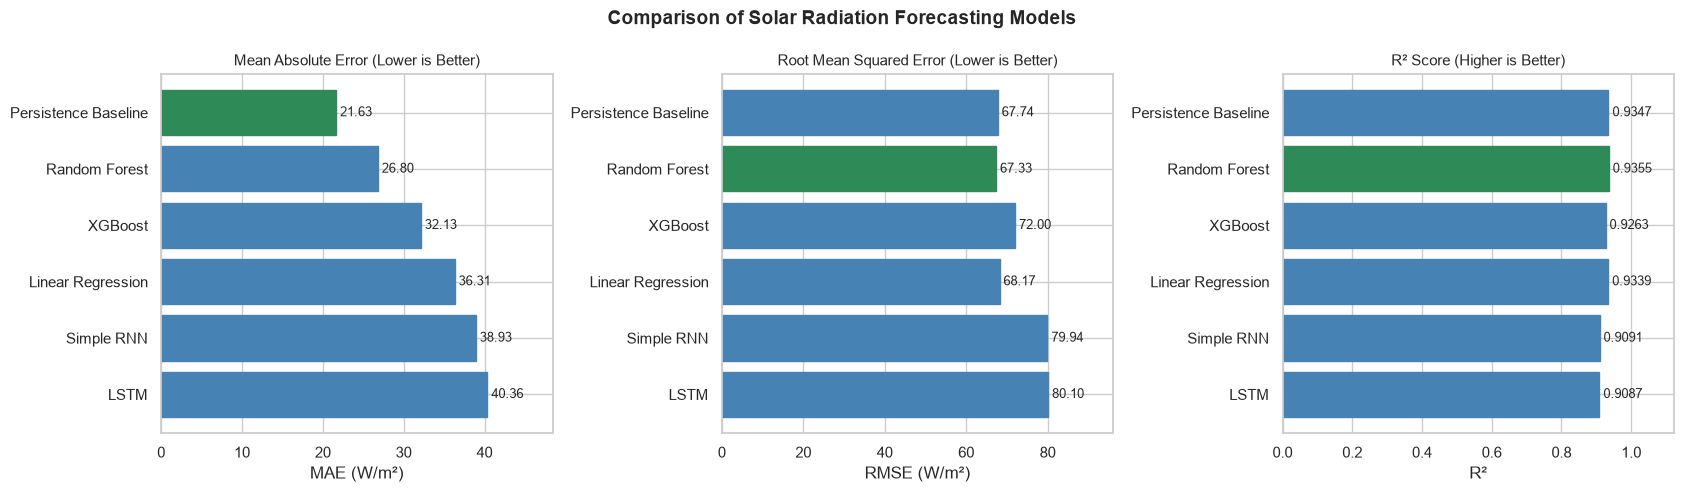

In [46]:

# Section 6.3 — Visual comparison of forecasting models

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

metrics = ["MAE (W/m²)", "RMSE (W/m²)", "R²"]
titles = [
    "Mean Absolute Error (Lower is Better)",
    "Root Mean Squared Error (Lower is Better)",
    "R² Score (Higher is Better)"
]

models = model_comparison["Model"]

for ax, metric, title in zip(axes, metrics, titles):
    values = model_comparison[metric]

    bars = ax.barh(models, values)

    # Highlight the best-performing model for each metric
    best_idx = values.idxmin() if metric != "R²" else values.idxmax()

    for bar, idx in zip(bars, model_comparison.index):
        if idx == best_idx:
            bar.set_color("seagreen")
        else:
            bar.set_color("steelblue")

    ax.set_title(title, fontsize=11)
    ax.set_xlabel(metric)
    ax.invert_yaxis()

    # Display metric values beside each bar
    for bar, value in zip(bars, values):
        label = f"{value:.4f}" if metric == "R²" else f"{value:.2f}"
        ax.text(
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2,
            f" {label}",
            va="center",
            fontsize=9
        )

    ax.set_xlim(0, values.max() * 1.20)

plt.suptitle(
    "Comparison of Solar Radiation Forecasting Models",
    fontsize=14,
    fontweight="bold"
)

# Adjust layout
plt.tight_layout()

# Save figure in the existing figures directory
fig.savefig(
    "../figures/model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

# Display figure
plt.show()



#### Interpretation of Model Performance Visualization

The comparative visualization illustrates the performance differences among the six forecasting models across MAE, RMSE, and R².

The Persistence Baseline achieved the lowest MAE of 21.63 W/m², indicating superior average absolute forecasting accuracy.

Random Forest recorded the lowest RMSE of 67.33 W/m² and the highest R² of 0.9355, demonstrating a slight advantage in reducing larger forecasting errors and explaining variations in solar radiation.

The Simple RNN and LSTM produced comparatively higher prediction errors, suggesting that their additional architectural complexity did not improve forecasting performance under the selected configurations.

Overall, the visualization reinforces the importance of evaluating complex forecasting models against simple baseline methods.

For the five-minute-ahead forecasting task, the Persistence Baseline provides the strongest MAE performance, while Random Forest achieves the best RMSE and R² results.



### 6.4 Forecasting Error Analysis

This subsection investigates the distribution of forecasting errors across the six models to provide additional insight into their predictive behavior.

While MAE, RMSE, and R² summarize overall forecasting performance, examining prediction errors helps identify systematic overestimation, underestimation, and variations in forecasting reliability.

Forecasting errors are defined as the difference between observed and predicted solar radiation:

**Forecasting Error = Actual Radiation − Predicted Radiation**

Positive errors indicate underprediction, while negative errors indicate overprediction.

The analysis uses the common evaluation dataset established in Section 6.1 and reuses the aligned predictions from Section 6.2.

The objective is to assess model bias and error variability without repeating previously completed performance comparisons.


In [47]:

# Section 6.4 — Forecasting error analysis

# Calculate residuals using existing aligned predictions
residuals = prediction_common[model_columns].rsub(
    prediction_common["Actual"], axis=0
)

# Summarize error distributions
error_summary = pd.DataFrame({
    "Mean Error (W/m²)": residuals.mean(),
    "Error Std. Dev. (W/m²)": residuals.std(),
    "Median Error (W/m²)": residuals.median(),
    "5th Percentile (W/m²)": residuals.quantile(0.05),
    "95th Percentile (W/m²)": residuals.quantile(0.95)
})

error_summary.index.name = "Model"

print("Forecasting Error Distribution Summary")
display(error_summary.round(2))


Forecasting Error Distribution Summary


,Mean Error (W/m²),Error Std. Dev. (W/m²),Median Error (W/m²),5th Percentile (W/m²),95th Percentile (W/m²)
Model,,,,,
Persistence Baseline,-0.12,67.75,0.00,-46.88,52.44
Linear Regression,0.93,68.17,1.12,-65.30,63.82
Random Forest,-0.45,67.33,0.00,-99.92,84.27
XGBoost,10.30,71.26,0.10,-75.00,124.00
Simple RNN,5.02,79.78,-0.07,-122.27,118.47
LSTM,10.97,79.35,-0.52,-100.64,155.11



#### Interpretation of Forecasting Error Analysis

The forecasting error analysis provides additional insight into model bias and prediction variability across the 6,320 common testing observations.

The Persistence Baseline exhibited the smallest mean forecasting error (-0.12 W/m²), indicating minimal overall systematic bias. Random Forest also demonstrated a low mean error (-0.45 W/m²) and achieved the lowest error standard deviation (67.33 W/m²), suggesting slightly more consistent predictions.

Linear Regression showed a relatively small positive mean error (0.93 W/m²), while XGBoost and LSTM exhibited greater average underprediction, with mean errors of 10.30 W/m² and 10.97 W/m², respectively.

The Simple RNN and LSTM displayed higher error variability than the conventional forecasting approaches, indicating greater dispersion in their prediction errors.

Although median errors were close to zero for most models, the wider error distributions indicate that substantial forecasting deviations still occur.

Overall, the results reinforce the effectiveness of the Persistence Baseline and Random Forest for short-term solar radiation forecasting. However, low average bias does not necessarily imply low individual prediction errors.

These findings demonstrate the importance of considering both systematic bias and error variability when assessing forecasting reliability.



### 6.5 Model Performance Under Different Solar Radiation Conditions

Solar radiation forecasting accuracy may vary depending on the intensity of incoming solar radiation.

This subsection evaluates the six forecasting models under three radiation conditions:

- **Low Radiation:** 0 ≤ Radiation < 200 W/m²
- **Moderate Radiation:** 200 ≤ Radiation < 600 W/m²
- **High Radiation:** Radiation ≥ 600 W/m²

These thresholds are selected as descriptive categories for this analysis rather than standardized meteorological classifications.

The objective is to determine whether forecasting models perform consistently across different radiation intensities or exhibit greater prediction errors under particular conditions.

The analysis uses the existing common evaluation dataset and previously generated predictions without repeating preprocessing, model training, or overall performance calculations.

Mean Absolute Error (MAE) is used to compare forecasting accuracy within each radiation category.


In [49]:

# Section 6.5 — Forecasting accuracy by solar radiation condition

# Define radiation intensity categories using actual observations
radiation_conditions = pd.cut(
    prediction_common["Actual"],
    bins=[-np.inf, 200, 600, np.inf],
    labels=["Low", "Moderate", "High"],
    right=False
)

# Calculate MAE for each model within each radiation category
condition_results = []

for condition in radiation_conditions.cat.categories:
    mask = radiation_conditions == condition
    actual = prediction_common.loc[mask, "Actual"]

    for model_name in model_columns:
        predicted = prediction_common.loc[mask, model_name]

        condition_results.append({
            "Radiation Condition": condition,
            "Model": model_name,
            "Observations": len(actual),
            "MAE (W/m²)": mean_absolute_error(actual, predicted)
        })

condition_comparison = pd.DataFrame(condition_results)

# Display model MAE across radiation conditions
condition_mae = condition_comparison.pivot(
    index="Model",
    columns="Radiation Condition",
    values="MAE (W/m²)"
).reindex(model_columns)

print("Model MAE by Solar Radiation Condition")
display(condition_mae.round(2))

print("\nNumber of observations by radiation condition:")
display(radiation_conditions.value_counts().sort_index())


Model MAE by Solar Radiation Condition


Radiation Condition,High,Low,Moderate
Persistence Baseline,50.92,5.43,77.19
Linear Regression,66.91,23.95,72.32
Random Forest,80.43,7.03,80.85
XGBoost,122.22,8.66,75.92
Simple RNN,78.66,16.69,115.54
LSTM,147.56,14.38,83.10



Number of observations by radiation condition:


Actual
Low         4623
Moderate     959
High         738
Name: count, dtype: int64


#### Interpretation of Model Performance Under Different Radiation Conditions

The radiation-condition analysis reveals substantial differences in forecasting accuracy across low, moderate, and high solar radiation intensities.

Under low-radiation conditions, the Persistence Baseline achieved the lowest MAE of 5.43 W/m², followed by Random Forest at 7.03 W/m². This indicates that recent radiation observations provide highly effective short-term predictions when radiation intensity is relatively low.

Under moderate-radiation conditions, Linear Regression achieved the lowest MAE of 72.32 W/m², outperforming the Persistence Baseline (77.19 W/m²) and the remaining models.

Under high-radiation conditions, the Persistence Baseline again demonstrated the strongest performance, recording an MAE of 50.92 W/m². The LSTM exhibited the highest error in this category (147.56 W/m²), suggesting limitations in its ability to forecast higher radiation values under the selected model configuration.

The testing observations were unevenly distributed across radiation categories. Low-radiation conditions accounted for 4,623 observations (73.1%), compared with 959 (15.2%) for moderate radiation and 738 (11.7%) for high radiation.

This imbalance is important when interpreting overall model performance, as the aggregate MAE is influenced by the number of observations within each category.

Overall, the findings demonstrate that forecasting performance is dependent on radiation intensity. The Persistence Baseline performs best under low- and high-radiation conditions, while Linear Regression achieves the lowest MAE under moderate-radiation conditions.

These results suggest that no single model consistently minimizes MAE across every radiation category. However, the Persistence Baseline remains the strongest overall model according to MAE.

Because the radiation categories are defined using observed target values, these findings represent retrospective model evaluation rather than a directly deployable model-selection strategy.



### 6.6 Model Selection and Practical Implications

#### Model Selection

The comparative evaluation of six forecasting approaches provides a basis for selecting a suitable model for five-minute-ahead solar radiation prediction.

Model selection considers the following criteria:

1. **Forecasting Accuracy:** Performance across MAE, RMSE, and R².
2. **Forecasting Reliability:** Systematic bias and variability in prediction errors.
3. **Model Complexity:** Computational requirements and implementation considerations.
4. **Performance Across Radiation Conditions:** Forecasting accuracy under low, moderate, and high radiation intensities.

Based on the evaluation results, the Persistence Baseline is selected as the preferred forecasting approach when minimizing Mean Absolute Error (MAE) is the primary objective.

The Persistence Baseline achieved the lowest overall MAE of 21.63 W/m² and demonstrated strong performance under low- and high-radiation conditions.

Random Forest is identified as the strongest alternative, achieving the lowest RMSE of 67.33 W/m² and the highest R² of 0.9355.

Although the Simple RNN and LSTM demonstrated predictive capability, their increased architectural complexity did not translate into improved forecasting accuracy under the selected configurations.

#### Practical Implications

The findings have several implications for short-term solar radiation forecasting and renewable energy applications.

**1. Importance of Recent Observations**

The strong performance of the Persistence Baseline demonstrates that recent solar radiation measurements contain substantial predictive information for five-minute-ahead forecasting.

**2. Model Complexity and Computational Efficiency**

The Persistence Baseline requires minimal computational resources and does not require model training, making it a practical choice for applications where simplicity, low computational cost, and frequent forecast updates are important.

**3. Potential Value of Random Forest**

Random Forest provides an alternative when reducing larger forecasting errors is prioritized, as reflected by its lower RMSE.

However, the observed RMSE improvement over the Persistence Baseline is relatively small, and further evaluation would be necessary to establish whether this advantage is operationally significant.

**4. Radiation-Dependent Forecasting Performance**

The results demonstrate that forecasting accuracy varies across radiation intensity categories. This suggests that future model development could investigate approaches designed to handle changing radiation conditions more effectively.

**5. Implications for Solar Energy Management**

Accurate short-term solar radiation forecasts can support photovoltaic power estimation, energy management, and operational planning.

However, translating radiation forecasts into electricity generation forecasts would require additional information about photovoltaic system characteristics and operating conditions.

#### Limitations of Model Selection

The model recommendation is based on the available dataset, selected forecasting horizon, and evaluation period.

The results do not establish that the Persistence Baseline will outperform more complex models under all geographical, seasonal, or meteorological conditions.

Furthermore, no formal statistical significance test has been conducted to establish whether the observed performance differences are statistically significant.

Additional evaluation across longer periods, different forecasting horizons, and alternative model configurations would strengthen the generalizability of the findings.

#### Final Recommendation

For the current five-minute-ahead solar radiation prediction task, the Persistence Baseline is recommended as the primary forecasting approach based on its superior MAE performance, low average bias, and minimal computational complexity.

Random Forest is recommended as a secondary candidate when RMSE and explained variance are prioritized.

Overall, the findings emphasize that forecasting model selection should be guided by demonstrated predictive performance and operational requirements rather than model complexity alone.
